<img src="https://img.shields.io/badge/Redes%20Complexas-UFRN%20%7C%20DCA-1f4e79?style=flat-square"> <img src="https://img.shields.io/badge/aula-Hubs-d62828?style=flat-square"> <img src="https://img.shields.io/badge/ferramentas-NetworkX%20%7C%20nxviz%20%7C%20Plotly%20%7C%20seaborn-555?style=flat-square">

# Hubs
## Medidas de centralidade e suas distribuições

> **Hub** (subst.) centro em torno do qual outras coisas giram ou do qual elas irradiam; um foco de atividade, autoridade, comércio, transporte etc.

Olhe pela janela de um avião ao sobrevoar uma cidade. Algumas avenidas concentram quase todo o fluxo, alguns cruzamentos parecem inevitáveis, alguns bairros só se ligam ao resto por uma única ponte. Redes sociais, redes de contato físico, malhas aéreas e a Internet têm exatamente essa anatomia. Esta aula é sobre **encontrar esses pontos especiais** e, mais difícil, sobre **discordar de nós mesmos** quando "importante" pode significar coisas diferentes.

### O que você vai levar desta aula

| Bloco | Pergunta que responde | Ferramenta |
|---|---|---|
| 1. Um grafo de bolso | Como enxergar uma rede antes de medi-la? | `nxviz`, `matplotlib` |
| 2. Geometria da rede | Onde ficam o "meio" e a "borda" de uma rede? | `eccentricity`, `diameter`, `periphery`, `radius`, `center` |
| 3. Ranking de nós | Quem é importante e por quê a resposta muda? | `degree`, `closeness`, `betweenness`, `eigenvector` |
| 4. Distribuições | Como descrever milhares de nós com uma curva? | histograma, PDF, KDE, CDF, ECDF |
| 5. SocioPatterns | O que uma exposição em Dublin ensina sobre rastreamento de contatos? | `pandas`, `seaborn`, `plotly` |
| 6. Ataque ao hub | Vale a pena proteger os hubs? | experimento de remoção |
| 7. Síntese | Qual centralidade para qual pergunta? | quiz com autocorreção |

### Como usar este notebook

* Execute as células na ordem. As células marcadas com **Desafio** pedem que você escreva código ou uma resposta antes de seguir.
* Cada desafio tem um **gabarito escondido** (clique em "Gabarito") que só faz sentido abrir depois de tentar.
* As figuras foram desenhadas seguindo princípios de **Gestalt**. Os quadros "Lente Gestalt" explicam qual princípio está em jogo, porque aprender a *ler* uma figura de rede é tão importante quanto calculá-la.
* As figuras interativas (Plotly) aceitam zoom, arraste e passagem do mouse sobre os nós. Use isso.

### Antes de qualquer cálculo, um palpite

Abaixo está a rede que vai nos acompanhar na primeira metade da aula. Ela tem 20 nós e 29 arestas.

Sem executar nada, olhe a lista de arestas na primeira célula de código da Seção 1 e responda mentalmente

1. Qual nó você apostaria que é o mais importante?
2. Qual nó está mais "no meio" da rede?
3. Esses dois nós são o mesmo?

Anote seu palpite na célula abaixo. Vamos voltar a ele no fim da aula.

In [1]:
# Escreva seu palpite (sem calcular nada ainda)
palpite = {
    "mais_importante": "?",   # ex.: "s"
    "mais_no_meio":    "?",   # ex.: "l"
    "sao_o_mesmo":     None,  # True / False
}
print("Palpite registrado. Vamos conferir no final.")

Palpite registrado. Vamos conferir no final.


# 1. Preparando o estúdio

Instalamos o `nxviz` (não vem no Colab) e montamos um pequeno **estúdio visual**. Duas funções vão fazer o trabalho pesado o resto da aula.

* `desenhar(...)` produz figuras estáticas com `matplotlib`, pensadas para impressão e para os slides.
* `grafo_interativo(...)` produz figuras `plotly` com passagem de mouse, zoom e um menu para trocar a métrica em exibição.

> **Lente Gestalt.** Toda figura deste notebook segue quatro regras. **Figura e fundo** (o que importa ganha cor forte, o resto vira cinza). **Similaridade** (mesma cor significa mesma categoria ou mesma faixa de valor). **Codificação redundante** (cor e tamanho dizem a mesma coisa, para que um leitor daltônico ou uma impressão em preto e branco não percam a mensagem). **Continuidade** (arestas finas e claras, para que o olho percorra caminhos sem tropeçar). Um mapa de cores sequencial de um só "calor", do cinza frio ao vermelho brasa, substitui o arco-íris `jet`, que inventa fronteiras onde não existem.

In [2]:
!pip install -q nxviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 21.2 MB/s eta 0:00:00


In [3]:
import sys, warnings, math, random, zlib, base64, io
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap, Normalize
import seaborn as sns
import plotly.graph_objects as go
import plotly.io as pio

import nxviz as nv
from nxviz import annotate

if "google.colab" in sys.modules:
    pio.renderers.default = "colab"

# ---------- paleta do estúdio ----------
FUNDO, TINTA, CINZA, CINZA_CLARO = "#fbfbf9", "#1f1f1f", "#9aa0a6", "#d9dce1"
BRASA = LinearSegmentedColormap.from_list(
    "brasa", ["#cfd6e0", "#f9c784", "#f28c28", "#d62828", "#6a040f"])
BRASA_PLOTLY = [[0, "#cfd6e0"], [0.25, "#f9c784"], [0.5, "#f28c28"],
                [0.75, "#d62828"], [1, "#6a040f"]]
CATEG = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]

plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 11,
})
sns.set_palette(CATEG)

def _escala(valores, lo=200, hi=1300):
    v = np.asarray(list(valores), dtype=float)
    if v.max() == v.min():
        return np.full_like(v, (lo + hi) / 2)
    return lo + (hi - lo) * (v - v.min()) / (v.max() - v.min())

def desenhar(g, valores, titulo="", pos=None, destaque=None, rotulo_barra="",
             ax=None, tamanho=(9, 7), anotar=True, vmin=None, vmax=None,
             cmap=BRASA, barra=True, aneis=None, rotulos=None,
             tam=(200, 1300), tamanho_inverso=False):
    '''Desenha g com cor E tamanho proporcionais a `valores` (dict no -> valor).

    destaque : nos que ficam em primeiro plano (os demais viram fundo cinza)
    aneis    : nos que recebem um anel escuro (fechamento / contorno)
    rotulos  : dict no -> texto; se for dado, SO esses nos recebem rotulo
    tam      : (menor, maior) area dos marcadores
    tamanho_inverso : True quando valor pequeno = mais importante (ex.: excentricidade)
    '''
    if pos is None:
        pos = nx.spring_layout(g, seed=123456789, k=0.3)
    if ax is None:
        fig, ax = plt.subplots(figsize=tamanho)
    else:
        fig = ax.figure
    nos = list(g.nodes())
    vals = np.array([valores[n] for n in nos], dtype=float)
    vmin = vals.min() if vmin is None else vmin
    vmax = vals.max() if vmax is None else vmax
    norm = Normalize(vmin=vmin, vmax=vmax)
    cores = cmap(norm(vals))
    tam = _escala(-vals if tamanho_inverso else vals, *tam)

    nx.draw_networkx_edges(g, pos, ax=ax, edge_color=CINZA_CLARO, width=1.4,
                           alpha=0.9 if g.number_of_edges() < 300 else 0.35)

    if destaque is not None:
        destaque = set(destaque)
        fundo = [n for n in nos if n not in destaque]
        frente = [n for n in nos if n in destaque]
        nx.draw_networkx_nodes(g, pos, nodelist=fundo, ax=ax, node_color=CINZA_CLARO,
                               node_size=[tam[nos.index(n)] * 0.45 for n in fundo],
                               alpha=0.8, linewidths=0)
        nx.draw_networkx_nodes(g, pos, nodelist=frente, ax=ax,
                               node_color=[cores[nos.index(n)] for n in frente],
                               node_size=[tam[nos.index(n)] for n in frente],
                               edgecolors=TINTA, linewidths=1.6)
        alvo_rotulo = frente
    else:
        nx.draw_networkx_nodes(g, pos, nodelist=nos, ax=ax, node_color=cores,
                               node_size=tam, edgecolors="white", linewidths=1.2)
        alvo_rotulo = nos

    if aneis:
        ax.scatter([pos[n][0] for n in aneis], [pos[n][1] for n in aneis],
                   s=[tam[nos.index(n)] * 2.4 for n in aneis], facecolors="none",
                   edgecolors=TINTA, linewidths=2, linestyle="--", zorder=4)

    if anotar:
        if rotulos:
            lab = {n: rotulos[n] for n in alvo_rotulo if n in rotulos}
        else:
            lab = {n: str(n) for n in alvo_rotulo}
        textos = nx.draw_networkx_labels(g, pos, labels=lab, ax=ax, font_size=10,
                                         font_weight="bold", font_color=TINTA)
        for t in textos.values():
            t.set_path_effects([pe.withStroke(linewidth=3, foreground="white")])

    if barra:
        sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
        cb = fig.colorbar(sm, ax=ax, fraction=0.035, pad=0.02)
        cb.set_label(rotulo_barra, rotation=270, labelpad=16)
        cb.outline.set_visible(False)
    ax.set_title(titulo, loc="left")
    ax.axis("off")
    return ax

def grafo_interativo(g, metricas, pos=None, titulo="", top_k=5, altura=620,
                     rotular_todos=False, tam_min=8, tam_max=34):
    '''Figura Plotly com um menu para trocar a metrica.

    metricas : dict nome -> dict(no -> valor). A primeira e a exibida por padrao.
    top_k    : quantos nos recebem rotulo (os maiores da metrica ativa)
    '''
    if pos is None:
        pos = nx.spring_layout(g, seed=123456789, k=0.3)
    nos = list(g.nodes())
    ex, ey = [], []
    for u, v in g.edges():
        ex += [pos[u][0], pos[v][0], None]; ey += [pos[u][1], pos[v][1], None]
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=ex, y=ey, mode="lines", hoverinfo="skip",
                             line=dict(color="#d9dce1", width=1), name="arestas"))
    nomes = list(metricas)
    for i, nome in enumerate(nomes):
        vals = np.array([metricas[nome][n] for n in nos], dtype=float)
        tam = _escala(vals, tam_min, tam_max)
        ordem = np.argsort(-vals)
        top = set(np.array(nos)[ordem[:top_k]].tolist())
        texto = [str(n) if (rotular_todos or n in top) else "" for n in nos]
        hover = []
        for n in nos:
            linhas = [f"<b>no {n}</b>", f"grau = {g.degree(n)}"]
            linhas += [f"{m} = {metricas[m][n]:.3f}" for m in nomes]
            hover.append("<br>".join(linhas))
        fig.add_trace(go.Scatter(
            x=[pos[n][0] for n in nos], y=[pos[n][1] for n in nos],
            mode="markers+text", text=texto, textposition="top center",
            textfont=dict(size=12, color=TINTA),
            hovertext=hover, hoverinfo="text", name=nome, visible=(i == 0),
            marker=dict(size=tam, color=vals, colorscale=BRASA_PLOTLY,
                        showscale=True, colorbar=dict(title=nome, thickness=12),
                        line=dict(color="white", width=1))))
    botoes = []
    for i, nome in enumerate(nomes):
        vis = [True] + [j == i for j in range(len(nomes))]
        botoes.append(dict(label=nome, method="update",
                           args=[{"visible": vis}, {"title": f"{titulo} · {nome}"}]))
    fig.update_layout(
        title=dict(text=f"{titulo} · {nomes[0]}", x=0.5, xanchor="center"),
        height=altura, showlegend=False,
        plot_bgcolor=FUNDO, paper_bgcolor=FUNDO, hovermode="closest",
        margin=dict(l=10, r=10, t=90, b=10),
        xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
        updatemenus=[dict(buttons=botoes, direction="down", x=0.0, y=1.15,
                          xanchor="left", yanchor="top", showactive=True)])
    return fig

def tabela_ranking(metricas, n=None):
    '''DataFrame com uma coluna por metrica, ordenado pela primeira, com barras.'''
    df = pd.DataFrame(metricas)
    df = df.sort_values(df.columns[0], ascending=False)
    if n: df = df.head(n)
    return df.style.bar(color="#f9c784", vmin=0).format("{:.3f}")

print("Estudio pronto. networkx", nx.__version__)

Estudio pronto. networkx 3.6.1


# 2. Um grafo de bolso

Antes de medir algo grande, treinamos o olhar em algo pequeno. O grafo abaixo é o mesmo dos slides. Repare que a lista de arestas está organizada por "família" de nós. Isso não é acaso. Ler uma lista de arestas é a forma mais primitiva de enxergar uma rede e ainda assim já dá para sentir que `l`, `n`, `o`, `k` e `s` formam um miolo denso.

In [4]:
g = nx.Graph()
g.add_edges_from([
    ('a','d'), ('b','e'), ('c','e'),
    ('d','i'), ('e','i'),
    ('f','h'), ('g','h'), ('h','i'), ('h','j'),
    ('i','l'), ('j','n'),
    ('l','m'), ('l','n'), ('l','k'), ('l','o'),
    ('m','u'),
    ('n','k'), ('n','o'), ('n','s'),
    ('o','k'), ('o','p'), ('o','s'),
    ('p','k'), ('p','s'),
    ('k','s'), ('k','u'),
    ('q','s'), ('r','s'),
    ('s','u'),
])

# guardamos o grau como atributo "classe" (vai servir de grupo para o nxviz)
for n in g.nodes():
    g.nodes[n]["classe"] = g.degree(n)

POS = nx.spring_layout(g, seed=123456789, k=0.3)   # posicao fixa para toda a aula
print(f"{g.number_of_nodes()} nos, {g.number_of_edges()} arestas, conexo = {nx.is_connected(g)}")

20 nos, 29 arestas, conexo = True


### 2.1 Três retratos da mesma rede (`nxviz`)

O `nxviz` implementa uma "gramática" de gráficos de rede. A ideia central é que **a posição dos nós é uma decisão de projeto**, não um acidente do algoritmo de layout. Três retratos da mesma rede contam três histórias.

* **Circos** (`nxviz`) coloca os nós num círculo, agrupados por uma categoria (aqui, o grau). As arestas que cruzam o centro denunciam ligações entre grupos diferentes.
* **Arc** (`nxviz`) coloca os nós numa linha e desenha as arestas como arcos. Arcos altos são ligações "de longo alcance" na ordenação escolhida.
* **Matriz de adjacência** com os nós ordenados por grau. O bloco denso no canto inferior direito é o miolo da rede.

> **Lente Gestalt.** No Circos, a **proximidade** (nós do mesmo grau ficam juntos) e a **similaridade** (mesma cor) trabalham em dupla. O olho agrupa antes de ler qualquer rótulo.

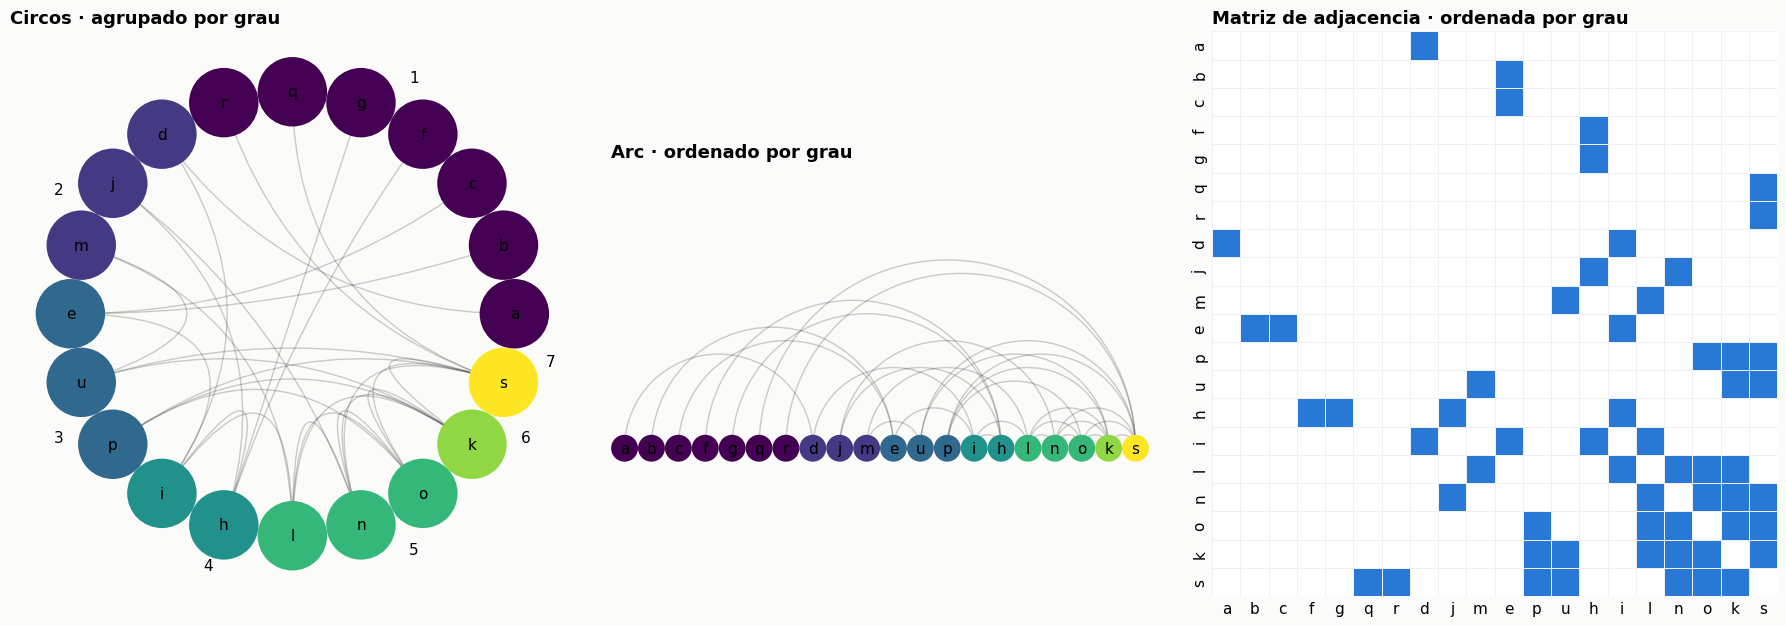

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

plt.sca(axes[0])
nv.circos(g, node_color_by="classe", group_by="classe", sort_by="classe")
annotate.circos_group(g, group_by="classe")
annotate.circos_labels(g, group_by="classe", sort_by="classe")
axes[0].set_title("Circos · agrupado por grau", loc="left")

plt.sca(axes[1])
nv.arc(g, node_color_by="classe", group_by="classe", sort_by="classe")
annotate.arc_labels(g, group_by="classe", sort_by="classe")
axes[1].set_title("Arc · ordenado por grau", loc="left")

ordem = sorted(g, key=lambda n: (g.degree(n), n))          # nos ordenados por grau
A = nx.to_numpy_array(g, nodelist=ordem)
sns.heatmap(A, ax=axes[2], cmap=["#ffffff", CATEG[0]], cbar=False, square=True,
            xticklabels=ordem, yticklabels=ordem, linewidths=0.5, linecolor="#eef0f3")
axes[2].set_title("Matriz de adjacencia · ordenada por grau", loc="left")
axes[2].tick_params(length=0)

for ax in axes[:2]: ax.axis("off")
plt.tight_layout(); plt.show()

### Desafio 1 · Olhar antes de medir

Olhando apenas para o retrato **Circos**, responda na célula abaixo

1. Qual grupo de grau tem mais arestas que cruzam o centro do círculo?
2. Existe algum nó de grau 1 conectado diretamente ao nó de maior grau? Quais?

Depois escreva uma linha de `networkx` que confirme a resposta 2.

<details>
<summary><b>Gabarito</b> (abra só depois de tentar)</summary>

```python
hub = max(g.degree, key=lambda x: x[1])[0]          # 's'
folhas = [n for n in g.neighbors(hub) if g.degree(n) == 1]
print(hub, folhas)                                   # s ['q', 'r']
```
Os nós `q` e `r` têm grau 1 e pendem diretamente de `s`. No Circos eles aparecem como arcos que saem do grupo "1" e cruzam o círculo até o grupo "7".
</details>

In [ ]:
# Desafio 1 · sua resposta aqui
resposta_1 = "grupo de grau ..."
resposta_2 = [...]
# confirmacao com networkx:

# 3. A geometria da rede

Vamos começar por perguntas geométricas. Onde fica o meio? Onde fica a borda? Para responder precisamos de uma única ideia, a **distância** entre dois nós, definida como o número de arestas do caminho mais curto entre eles.

| Conceito | Definição | `networkx` |
|---|---|---|
| **Excentricidade** de um nó | a maior distância desse nó até qualquer outro nó | `nx.eccentricity(g)` |
| **Diâmetro** | a maior excentricidade da rede | `nx.diameter(g)` |
| **Periferia** | conjunto dos nós cuja excentricidade é igual ao diâmetro | `nx.periphery(g)` |
| **Raio** | a menor excentricidade da rede | `nx.radius(g)` |
| **Centro** | conjunto dos nós cuja excentricidade é igual ao raio | `nx.center(g)` |

Uma imagem mental que ajuda. Pense na excentricidade como a "altitude" de cada nó. O centro é o fundo do vale (quem consegue alcançar todo mundo com poucos passos). A periferia é o topo das montanhas.

In [6]:
ecc = nx.eccentricity(g)
ecc

{'a': 6,
 'd': 5,
 'b': 6,
 'e': 5,
 'c': 6,
 'i': 4,
 'f': 5,
 'h': 4,
 'g': 5,
 'j': 4,
 'l': 3,
 'n': 4,
 'm': 4,
 'k': 4,
 'o': 4,
 'u': 5,
 's': 5,
 'p': 5,
 'q': 6,
 'r': 6}

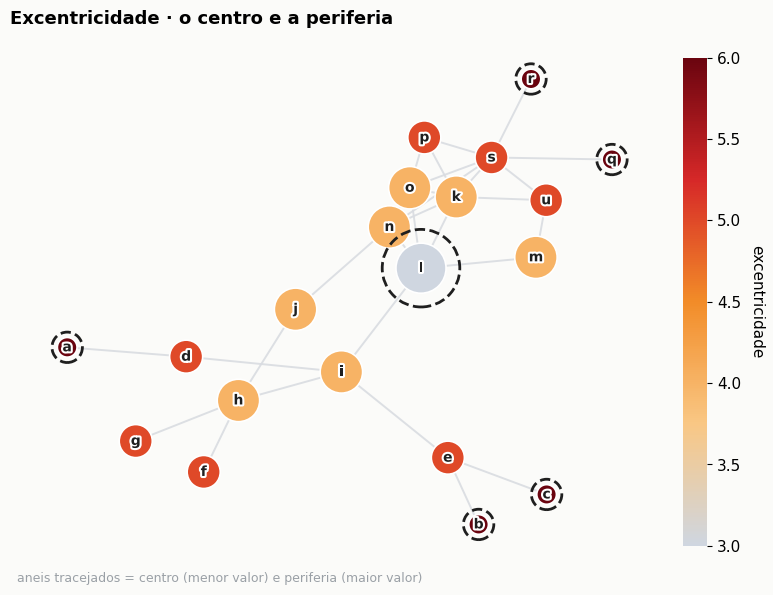

In [7]:
ax = desenhar(g, ecc, pos=POS, titulo="Excentricidade · o centro e a periferia",
              rotulo_barra="excentricidade", tamanho_inverso=True,
              aneis=nx.center(g) + nx.periphery(g))
ax.text(0.01, -0.02, "aneis tracejados = centro (menor valor) e periferia (maior valor)",
        transform=ax.transAxes, fontsize=9, color=CINZA)
plt.show()

In [8]:
print("Diametro      :", nx.diameter(g), "  ->  periferia", nx.periphery(g))
print("Raio          :", nx.radius(g),   "  ->  centro   ", nx.center(g))

# as mesmas listas obtidas "na mao" a partir da excentricidade
print("periferia (na mao):", [k for k, v in ecc.items() if v == nx.diameter(g)])
print("centro    (na mao):", [k for k, v in ecc.items() if v == nx.radius(g)])

Diametro      : 6   ->  periferia ['a', 'b', 'c', 'q', 'r']
Raio          : 3   ->  centro    ['l']
periferia (na mao): ['a', 'b', 'c', 'q', 'r']
centro    (na mao): ['l']


### 3.1 A rede vista de dentro do centro

Se `l` é o centro, como a rede se organiza em torno dele? A função `nx.bfs_layers` devolve as "camadas" de uma busca em largura. Cada camada é o conjunto de nós a uma mesma distância do centro. Desenhar as camadas como anéis concêntricos (layout `shell`) transforma a excentricidade em algo literalmente visível. O raio da rede é o número de anéis.

> **Lente Gestalt.** O layout em conchas usa **proximidade** (mesma distância, mesmo anel) e **fechamento** (o olho completa os círculos mesmo sem que eles estejam desenhados).

distancia 0: ['l']
distancia 1: ['i', 'k', 'm', 'n', 'o']
distancia 2: ['d', 'e', 'h', 'j', 'p', 's', 'u']
distancia 3: ['a', 'b', 'c', 'f', 'g', 'q', 'r']


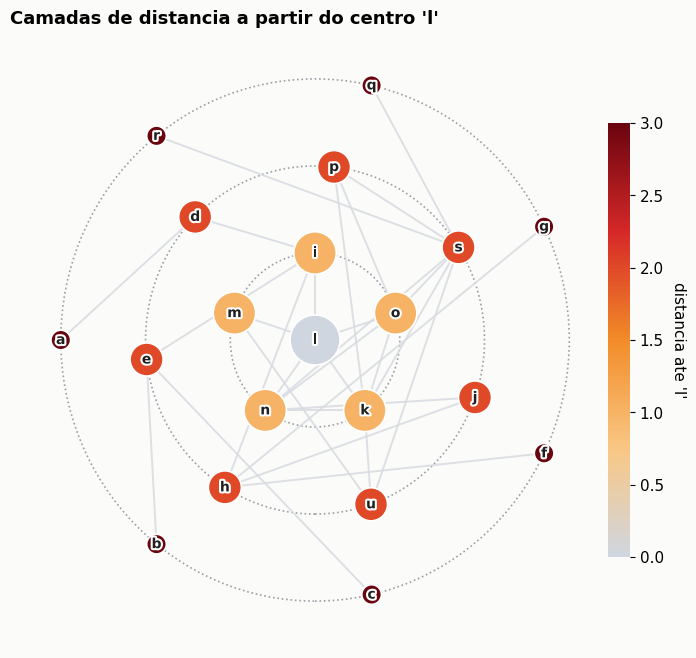

In [9]:
centro = nx.center(g)[0]
camadas = list(nx.bfs_layers(g, centro))
for d, camada in enumerate(camadas):
    print(f"distancia {d}: {sorted(camada)}")

pos_conchas = nx.shell_layout(g, nlist=camadas)
dist_centro = {n: d for d, camada in enumerate(camadas) for n in camada}

fig, ax = plt.subplots(figsize=(8, 8))
for r in range(1, len(camadas)):
    ax.add_patch(plt.Circle((0, 0), r / len(camadas), fill=False,
                            ls=":", color=CINZA, lw=1.2))
desenhar(g, dist_centro, pos=pos_conchas, ax=ax, tamanho_inverso=True,
         titulo=f"Camadas de distancia a partir do centro '{centro}'",
         rotulo_barra=f"distancia ate '{centro}'", cmap=BRASA)
plt.show()

### Desafio 2 · Implemente a excentricidade

`nx.eccentricity` é uma linha. Mas você entendeu o que ela faz? Escreva uma função `excentricidade(g, no)` usando apenas `nx.shortest_path_length(g, source=no)` e confirme que o resultado bate com o do `networkx` para todos os nós.

Em seguida responda. O que acontece com o diâmetro se removermos a aresta `('h', 'i')`? Faça a "cirurgia" numa **cópia** do grafo e explique o resultado em uma frase.

<details>
<summary><b>Gabarito</b></summary>

```python
def excentricidade(g, no):
    return max(nx.shortest_path_length(g, source=no).values())

assert all(excentricidade(g, n) == nx.eccentricity(g)[n] for n in g)

g_cirurgia = g.copy()
g_cirurgia.remove_edge('h', 'i')
print(nx.is_connected(g_cirurgia), nx.diameter(g_cirurgia), nx.center(g_cirurgia))
```
A rede continua conexa (existe o desvio `h-j-n`), mas o diâmetro sobe de 6 para 7 e o raio de 3 para 4. O caminho `a-d-i-h-f`, que antes tinha 4 passos, agora precisa dar a volta por `l-n-j-h`. O centro deixa de ser só `l` e passa a ser `l, n, k, o`, e `f` e `g` entram na periferia. Removemos uma aresta de dois nós que **não** estavam nem no centro nem na periferia e ainda assim os dois conjuntos mudaram. A geometria da rede é global.
</details>

In [ ]:
# Desafio 2 · sua implementacao
def excentricidade(g, no):
    ...

# cirurgia
g_cirurgia = g.copy()

# 4. Ranking de nós

> Quanto mais amigos uma pessoa tem, mais importante ela é?
> E se existir uma pessoa com poucos amigos, mas posicionada entre comunidades diferentes?

O slide mostra duas comunidades densas ligadas por um único nó. Vamos construir exatamente esse cenário com `nx.barbell_graph` e deixar os números falarem.

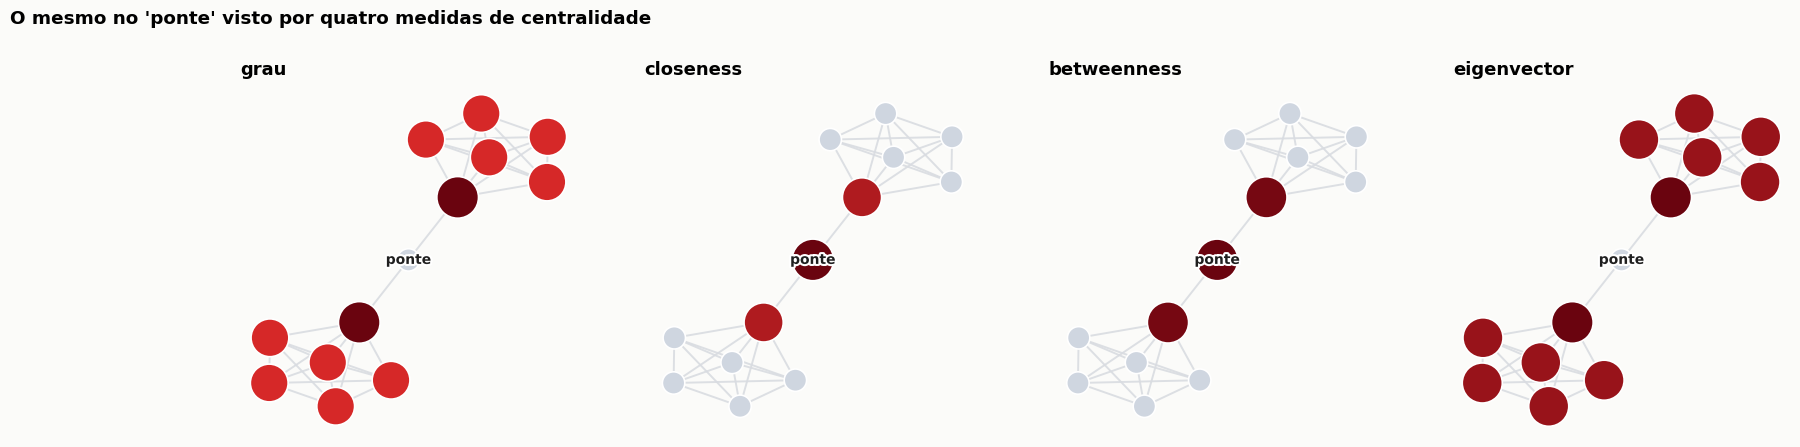

,grau,closeness,betweenness,eigenvector
no da clique,0.417,0.400,0.000,0.283
no de contato,0.500,0.522,0.530,0.303
PONTE,0.167,0.545,0.545,0.120


In [10]:
haltere = nx.barbell_graph(6, 1)       # duas cliques de 6 nos ligadas por um no "ponte"
ponte = 6                              # o no do meio

metricas_haltere = {
    "grau":          nx.degree_centrality(haltere),
    "closeness":     nx.closeness_centrality(haltere),
    "betweenness":   nx.betweenness_centrality(haltere),
    "eigenvector":   nx.eigenvector_centrality(haltere, max_iter=1000),
}
pos_h = nx.kamada_kawai_layout(haltere)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (nome, vals) in zip(axes, metricas_haltere.items()):
    desenhar(haltere, vals, pos=pos_h, ax=ax, titulo=nome, barra=False,
             rotulos={ponte: "ponte"}, tam=(260, 900))
plt.suptitle("O mesmo no 'ponte' visto por quatro medidas de centralidade",
             x=0.01, y=1.04, ha="left", fontweight="bold")
plt.show()

pd.DataFrame(metricas_haltere).loc[[0, 5, ponte]].rename(index={0: "no da clique", 5: "no de contato", ponte: "PONTE"}).round(3)

A ponte tem o **menor grau** da rede e ao mesmo tempo o **maior betweenness**. Nenhuma das quatro medidas está errada. Elas respondem perguntas diferentes.

| Medida | Pergunta que responde | Fórmula | `networkx` |
|---|---|---|---|
| **Degree centrality** | Quantas conexões diretas o nó tem? | $C_D(i) = \dfrac{k_i}{N-1}$ | `nx.degree_centrality` |
| **Closeness centrality** | Quão perto o nó está de todos os outros? | $C_C(i) = \dfrac{N-1}{\sum_{j \neq i} \ell_{ij}}$ | `nx.closeness_centrality` |
| **Betweenness centrality** | Em quantos caminhos mais curtos o nó está no meio? | $C_B(i) = \sum_{h \neq j \neq i} \dfrac{\sigma_{hj}(i)}{\sigma_{hj}}$ | `nx.betweenness_centrality` |
| **Eigenvector centrality** | O nó está ligado a nós que são, eles mesmos, importantes? | $x_i = \kappa^{-1} \sum_j A_{ij} x_j$ | `nx.eigenvector_centrality` |

Nas fórmulas, $N$ é o número de nós, $k_i$ o grau, $\ell_{ij}$ a distância entre $i$ e $j$, $\sigma_{hj}$ o número de caminhos mais curtos entre $h$ e $j$, e $\sigma_{hj}(i)$ quantos desses passam por $i$.

## 4.1 Degree centrality · número de conexões

A mais simples e, por isso mesmo, a mais usada. Dividir pelo máximo possível ($N-1$) coloca o valor entre 0 e 1 e permite comparar redes de tamanhos diferentes. Repare que a figura do grau bruto e a da centralidade de grau são **idênticas**. Só a barra de cores muda de escala.

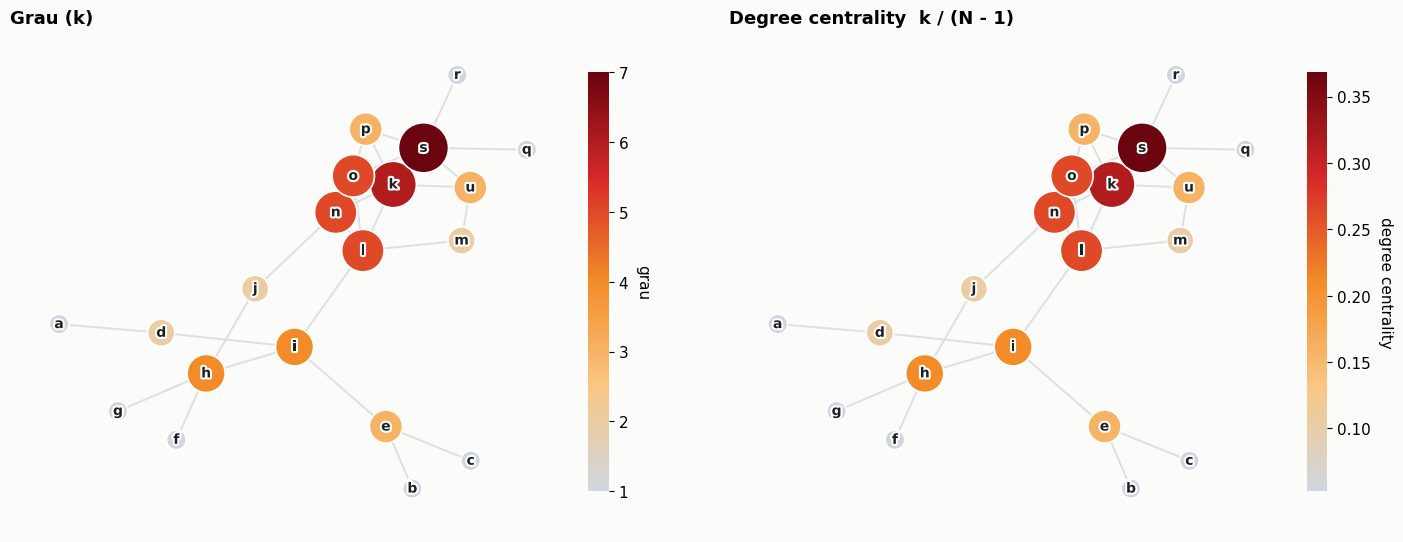

,degree
s,0.368
k,0.316
n,0.263
l,0.263
o,0.263
i,0.211


In [11]:
grau = dict(g.degree())
grau_c = nx.degree_centrality(g)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
desenhar(g, grau,   pos=POS, ax=axes[0], titulo="Grau (k)", rotulo_barra="grau")
desenhar(g, grau_c, pos=POS, ax=axes[1], titulo="Degree centrality  k / (N - 1)", rotulo_barra="degree centrality")
plt.show()

# conferindo a formula na mao
N = g.number_of_nodes()
assert all(abs(grau[n] / (N - 1) - grau_c[n]) < 1e-12 for n in g)
tabela_ranking({"degree": grau_c}, n=6)

## 4.2 Closeness centrality · distância média aos outros

Outra forma de medir centralidade é perguntar quão "perto" um nó está de todos os demais. Somamos as distâncias do nó até cada um dos outros e invertemos. Nós com alto closeness espalham (ou recebem) informação em poucos passos.

Compare com a figura da excentricidade. O centro `l` continua bem colocado, mas agora `i` aparece com força. A excentricidade olha só para o **pior caso** (o nó mais distante). O closeness olha para a **média**. `i` está a 4 passos do nó mais distante, mas na média está perto de todo mundo.

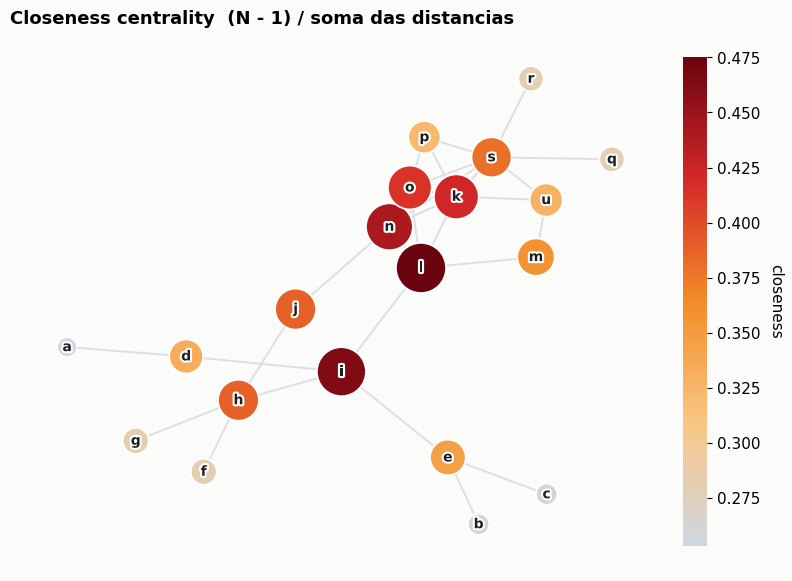

,closeness
l,0.475
i,0.463
n,0.442
k,0.422
o,0.413
h,0.388


In [12]:
closeness = nx.closeness_centrality(g)

def closeness_na_mao(g, no):
    dist = nx.shortest_path_length(g, source=no)
    return (len(g) - 1) / sum(d for alvo, d in dist.items() if alvo != no)

assert all(abs(closeness_na_mao(g, n) - closeness[n]) < 1e-12 for n in g)

desenhar(g, closeness, pos=POS, titulo="Closeness centrality  (N - 1) / soma das distancias",
         rotulo_barra="closeness")
plt.show()
tabela_ranking({"closeness": closeness}, n=6)

## 4.3 Betweenness centrality · posição nos caminhos mais curtos

Muitos fenômenos em redes são processos de **difusão**. A transmissão de uma informação numa rede social, o tráfego de mercadorias num porto, a propagação de uma epidemia numa rede de contatos físicos. Isso sugere uma terceira noção de centralidade, chamada *betweenness* (intermediação). Um nó é tanto mais central quanto mais frequentemente ele está envolvido nesses processos, ou seja, quanto mais caminhos mais curtos passam por ele.

A implementação "na mão" abaixo é ingênua (enumera todos os caminhos mais curtos de todos os pares), mas deixa a fórmula transparente. O `networkx` usa o algoritmo de Brandes, muito mais rápido, e normaliza o resultado dividindo por $\frac{(N-1)(N-2)}{2}$ em grafos não dirigidos.

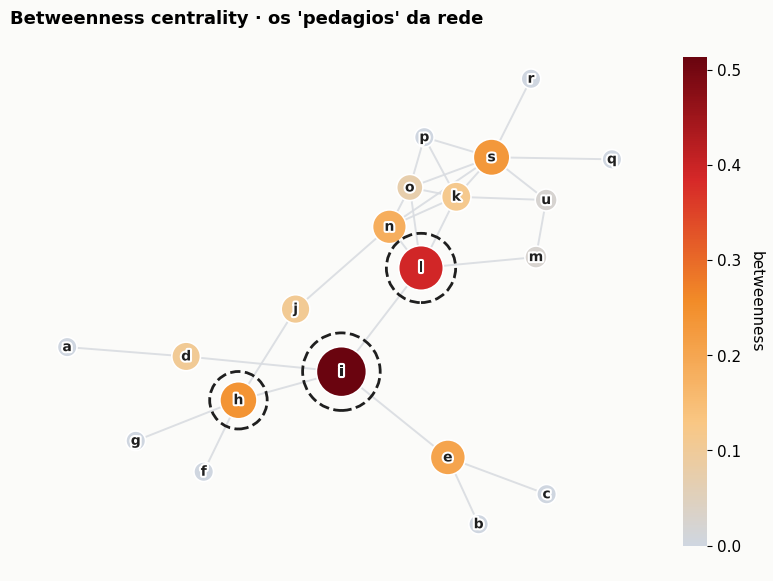

,betweenness
i,0.513
l,0.390
h,0.240
s,0.230
e,0.205
n,0.183


In [13]:
betweenness = nx.betweenness_centrality(g)

def betweenness_na_mao(g):
    nos = list(g); bc = {n: 0.0 for n in nos}
    for a_idx, h in enumerate(nos):
        for j in nos[a_idx + 1:]:
            caminhos = list(nx.all_shortest_paths(g, h, j))
            sigma_hj = len(caminhos)
            for caminho in caminhos:
                for i in caminho[1:-1]:                 # so os nos do meio
                    bc[i] += 1 / sigma_hj
    N = len(nos)
    return {n: v / ((N - 1) * (N - 2) / 2) for n, v in bc.items()}

bc_mao = betweenness_na_mao(g)
assert all(abs(bc_mao[n] - betweenness[n]) < 1e-9 for n in g)

top3 = sorted(betweenness, key=betweenness.get, reverse=True)[:3]
desenhar(g, betweenness, pos=POS, titulo="Betweenness centrality · os 'pedagios' da rede",
         rotulo_barra="betweenness", aneis=top3)
plt.show()
tabela_ranking({"betweenness": betweenness}, n=6)

### Desafio 3 · O pedágio invisível

`i` tem grau 4 e o **maior** betweenness da rede. `s` tem grau 7 e ficou atrás. Explique, em uma frase, por que isso acontece. Em seguida, encontre **uma única aresta** que, adicionada ao grafo, faça o betweenness de `i` cair mais de 30%. Use uma cópia do grafo e mostre antes e depois.

<details>
<summary><b>Gabarito</b></summary>

`i` é a única porta de entrada do "braço" formado por `a, b, c, d, e` e ao mesmo tempo o caminho natural entre `h, f, g` e o miolo. Todo caminho mais curto entre esses dois mundos passa por `i`. `s` tem muitos vizinhos, mas todos eles também se enxergam por outros caminhos.

```python
g2 = g.copy(); g2.add_edge('e', 'l')          # um "atalho" que desvia de i
antes  = nx.betweenness_centrality(g)['i']
depois = nx.betweenness_centrality(g2)['i']
print(f"antes {antes:.3f}  depois {depois:.3f}  ({depois/antes:.0%} do valor original)")
```
`e-l` derruba o betweenness de `i` para 64% do valor original. Qualquer aresta que ligue o braço `a..e` diretamente ao miolo (`d-n`, `e-j`) produz efeito parecido. Uma única aresta muda drasticamente a importância de um nó que nem foi tocado. Betweenness é uma propriedade **da rede**, não do nó.
</details>

In [ ]:
# Desafio 3 · sua resposta
explicacao = "..."
g_atalho = g.copy()
# g_atalho.add_edge(?, ?)

## 4.4 Eigenvector centrality · a importância dos seus vizinhos

Em muitas situações a importância de um nó cresce quando ele está ligado a nós que são, eles próprios, importantes. Você pode ter um único amigo no mundo, mas se esse amigo for o CR7, você provavelmente é uma pessoa importante. Centralidade não é só sobre **quantas** pessoas você conhece, mas sobre **quem** você conhece.

Newman (*Networks*, cap. 7) formaliza a ideia. A centralidade $x_i$ do nó $i$ é proporcional à soma das centralidades dos vizinhos

$$x_i = \kappa^{-1} \sum_{j=1}^{n} A_{ij}\, x_j \qquad \Longleftrightarrow \qquad A\,x = \kappa\, x$$

Ou seja, $x$ é um **autovetor** da matriz de adjacência $A$ e $\kappa$ o autovalor correspondente. O algoritmo que o `networkx` usa (`eigenvector_centrality(G, max_iter=100, tol=1e-6, nstart=None, weight=None)`) é o **método da potência**. Começa com todos os nós valendo 1, multiplica pela matriz de adjacência, normaliza, e repete até convergir.

### 4.4.1 O método da potência, iteração por iteração

Vamos reproduzir o exemplo de Meghanathan (2015) mostrado nos slides, com 8 nós, para ver o vetor convergir.

In [14]:
g8 = nx.Graph([(1,2),(1,3),(2,4),(2,8),(3,4),(3,7),(4,7),(5,6),(5,8),(6,7)])
A = nx.to_numpy_array(g8, nodelist=sorted(g8))
print("Matriz de adjacencia A\n", A.astype(int))

def metodo_da_potencia(A, iteracoes=5):
    x = np.ones(A.shape[0])
    historico = [x / np.linalg.norm(x)]
    for _ in range(iteracoes):
        y = A @ x
        norma = np.linalg.norm(y)
        x = y / norma
        historico.append(x)
    return historico, norma

hist, kappa = metodo_da_potencia(A, iteracoes=5)
tab = pd.DataFrame(np.array(hist).T, index=[f"no {i}" for i in sorted(g8)],
                   columns=[f"iter {i}" for i in range(len(hist))])
tab["networkx"] = pd.Series(nx.eigenvector_centrality(g8)).sort_index().values
print(f"\nautovalor dominante (kappa) ~ {kappa:.3f}")
tab.style.background_gradient(cmap=BRASA, axis=None).format("{:.3f}")

Matriz de adjacencia A
 [[0 1 1 0 0 0 0 0]
 [1 0 0 1 0 0 0 1]
 [1 0 0 1 0 0 1 0]
 [0 1 1 0 0 0 1 0]
 [0 0 0 0 0 1 0 1]
 [0 0 0 0 1 0 1 0]
 [0 0 1 1 0 1 0 0]
 [0 1 0 0 1 0 0 0]]

autovalor dominante (kappa) ~ 2.660


,iter 0,iter 1,iter 2,iter 3,iter 4,iter 5,networkx
no 1,0.354,0.277,0.316,0.298,0.321,0.306,0.316
no 2,0.354,0.416,0.369,0.397,0.366,0.388,0.375
no 3,0.354,0.416,0.422,0.457,0.449,0.467,0.465
no 4,0.354,0.416,0.474,0.457,0.486,0.469,0.481
no 5,0.354,0.277,0.211,0.199,0.172,0.174,0.161
no 6,0.354,0.277,0.264,0.238,0.239,0.228,0.226
no 7,0.354,0.416,0.422,0.437,0.434,0.441,0.441
no 8,0.354,0.277,0.264,0.219,0.224,0.202,0.201


Compare a coluna `iter 5` com a coluna `networkx`. Depois de cinco multiplicações o vetor já está a duas casas decimais da resposta. Repare também que na `iter 1` o vetor é simplesmente o **grau normalizado** de cada nó. Eigenvector centrality começa como grau e vai "aprendendo" quem são os vizinhos importantes.

Agora o mesmo processo animado, no nosso grafo de 20 nós. Arraste o controle deslizante e veja as cores se estabilizarem.

In [15]:
A20 = nx.to_numpy_array(g, nodelist=list(g))
hist20, _ = metodo_da_potencia(A20, iteracoes=12)
nos = list(g)

ex, ey = [], []
for u, v in g.edges():
    ex += [POS[u][0], POS[v][0], None]; ey += [POS[u][1], POS[v][1], None]

def _marcadores(vec):
    return go.Scatter(x=[POS[n][0] for n in nos], y=[POS[n][1] for n in nos],
                      mode="markers+text", text=nos, textposition="middle center",
                      textfont=dict(size=11, color="white"),
                      hovertext=[f"{n}: {v:.3f}" for n, v in zip(nos, vec)], hoverinfo="text",
                      marker=dict(size=_escala(vec, 14, 44), color=vec, cmin=0, cmax=0.5,
                                  colorscale=BRASA_PLOTLY, showscale=True,
                                  colorbar=dict(title="x_i", thickness=12),
                                  line=dict(color="white", width=1)))

frames = [go.Frame(data=[_marcadores(v)], traces=[1], name=str(i)) for i, v in enumerate(hist20)]
fig = go.Figure(data=[go.Scatter(x=ex, y=ey, mode="lines", hoverinfo="skip",
                                 line=dict(color="#d9dce1", width=1)), _marcadores(hist20[0])],
                frames=frames)
fig.update_layout(
    title=dict(text="Metodo da potencia · o vetor de centralidade convergindo", x=0.5),
    height=620, plot_bgcolor=FUNDO, paper_bgcolor=FUNDO, showlegend=False,
    xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
    margin=dict(l=10, r=10, t=90, b=10),
    updatemenus=[dict(type="buttons", x=0, y=1.15, xanchor="left", yanchor="top",
                      buttons=[dict(label="Reproduzir", method="animate",
                                    args=[None, {"frame": {"duration": 600}, "fromcurrent": True}])])],
    sliders=[dict(steps=[dict(method="animate", label=f"iter {i}",
                              args=[[str(i)], {"frame": {"duration": 0}, "mode": "immediate"}])
                        for i in range(len(hist20))], x=0.15, len=0.85)])
fig.show()

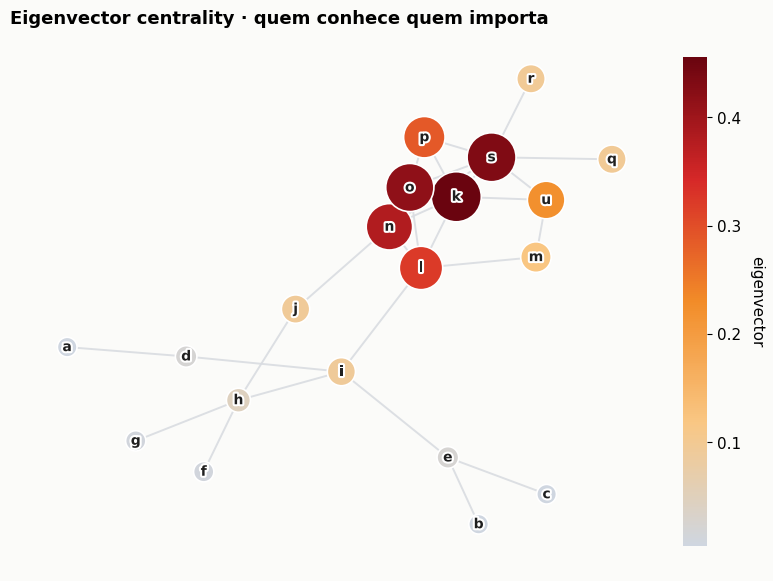

,eigenvector
k,0.455
s,0.431
o,0.415
n,0.380
l,0.323
p,0.288


In [16]:
eigen = nx.eigenvector_centrality(g)
desenhar(g, eigen, pos=POS, titulo="Eigenvector centrality · quem conhece quem importa",
         rotulo_barra="eigenvector")
plt.show()
tabela_ranking({"eigenvector": eigen}, n=6)

### Desafio 4 · Quem é o "amigo do CR7"?

Encontre, no grafo `g`, o nó cujo eigenvector centrality é **mais alto do que o grau dele sugere**. Uma forma de fazer isso é comparar a posição (ranking) de cada nó nas duas medidas e procurar a maior diferença. Explique o resultado olhando os vizinhos desse nó.

<details>
<summary><b>Gabarito</b></summary>

```python
rk = pd.DataFrame({"grau": grau_c, "eigen": eigen}).rank(ascending=False)
rk["salto"] = rk["grau"] - rk["eigen"]          # positivo = subiu no eigenvector
print(rk.sort_values("salto", ascending=False).head(3))
print(list(g.neighbors(rk["salto"].idxmax())))
```
`q` e `r` sobem sete posições. Eles têm grau 1, o menor possível, mas o único vizinho deles é `s`, o nó mais central da rede. São literalmente os "amigos do CR7". `m` e `p` também sobem, porque todos os seus vizinhos vivem no miolo denso. No sentido oposto, `h` e `i` despencam (mais de cinco posições) apesar do grau 4, porque a maioria dos seus vizinhos são folhas ou nós de grau 2.
</details>

In [ ]:
# Desafio 4 · sua resposta

## 4.5 As quatro medidas lado a lado

Agora as quatro figuras na **mesma escala de cor** (0 a 0,52, o maior valor entre todas). Isso é fundamental. Escalas diferentes em cada painel fariam o olho comparar coisas incomparáveis.

> **Lente Gestalt.** Pequenos múltiplos exploram a **similaridade** (mesmo layout, mesma escala) para que a única diferença perceptível seja a que importa. Se o layout mudasse de um painel para outro, o cérebro gastaria energia "re-reconhecendo" a rede em vez de comparar as cores.

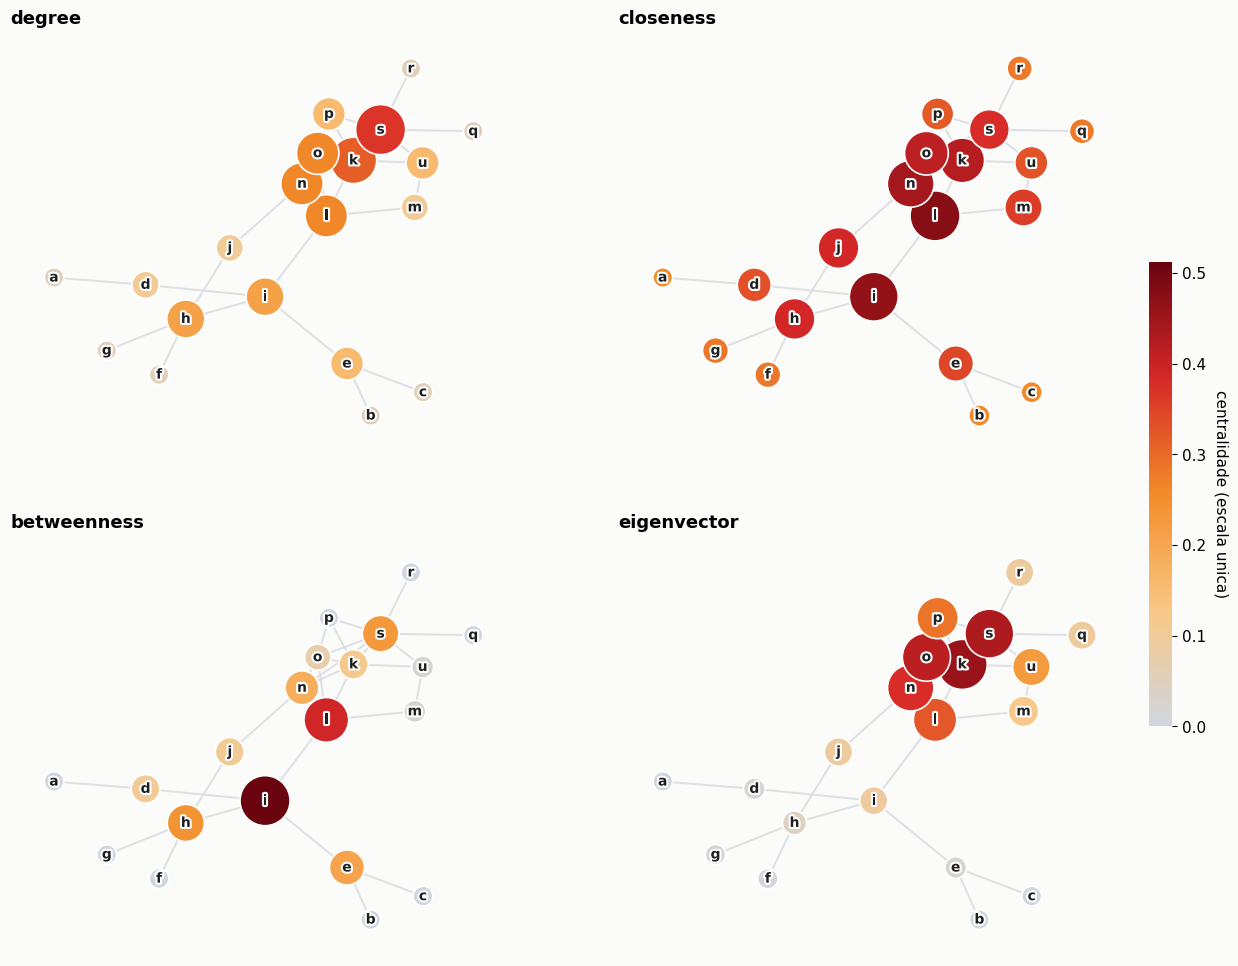

In [17]:
metricas = {"degree": grau_c, "closeness": closeness, "betweenness": betweenness, "eigenvector": eigen}
vmax = max(max(v.values()) for v in metricas.values())

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, (nome, vals) in zip(axes.ravel(), metricas.items()):
    desenhar(g, vals, pos=POS, ax=ax, titulo=nome, vmin=0, vmax=vmax, barra=False)
sm = mpl.cm.ScalarMappable(cmap=BRASA, norm=Normalize(0, vmax)); sm.set_array([])
cb = fig.colorbar(sm, ax=axes, fraction=0.02, pad=0.02); cb.outline.set_visible(False)
cb.set_label("centralidade (escala unica)", rotation=270, labelpad=16)
plt.show()

### 4.6 A mesma comparação, interativa

Use o menu no canto superior esquerdo para trocar a métrica. Passe o mouse sobre um nó para ver **todas** as medidas de uma vez. Repare como `i` e `s` trocam de lugar dependendo da pergunta.

In [18]:
grafo_interativo(g, metricas, pos=POS, titulo="Grafo de bolso", top_k=4, rotular_todos=True).show()

### 4.7 O gráfico de "salto de posições"

Uma figura de rede é ótima para ver **onde** as coisas acontecem, mas ruim para ver **quanto**. O gráfico abaixo (chamado *bump chart*) mostra a posição de cada nó no ranking de cada medida. Linhas quase horizontais são nós "consistentes". Linhas em zigue-zague são nós cuja importância depende da pergunta.

> **Lente Gestalt.** A **continuidade** das linhas faz o olho seguir cada nó através das quatro medidas sem precisar ler rótulos. Só os nós com maior variação recebem cor; os demais viram fundo.

In [19]:
ranks = pd.DataFrame(metricas).rank(ascending=False, method="min")
variacao = (ranks.max(axis=1) - ranks.min(axis=1)).sort_values(ascending=False)
destaques = variacao.index[:5].tolist()

fig = go.Figure()
for n in ranks.index:
    em_destaque = n in destaques
    fig.add_trace(go.Scatter(
        x=list(ranks.columns), y=ranks.loc[n].values, mode="lines+markers+text",
        text=[n if em_destaque else "", "", "", n],
        textposition=["middle left", "top center", "top center", "middle right"],
        name=str(n), hovertemplate=f"no {n}<br>%{{x}}: posicao %{{y}}<extra></extra>",
        line=dict(width=3 if em_destaque else 1,
                  color=CATEG[destaques.index(n)] if em_destaque else "#d9dce1"),
        marker=dict(size=9 if em_destaque else 5), opacity=1 if em_destaque else 0.8,
        textfont=dict(color=CATEG[destaques.index(n)] if em_destaque else "#b0b4ba", size=11)))
fig.update_layout(title="Posicao no ranking em cada medida (1 = mais central)", height=650,
                  yaxis=dict(range=[20.8, 0.2], title="posicao", dtick=1, gridcolor="#eee"),
                  xaxis=dict(title=""), plot_bgcolor=FUNDO, paper_bgcolor=FUNDO,
                  showlegend=False, margin=dict(l=40, r=40, t=60, b=40))
fig.show()
print("nos que mais mudam de posicao:", dict(variacao.head(5)))

nos que mais mudam de posicao: {'i': np.float64(11.0), 'h': np.float64(10.0), 'e': np.float64(9.0), 'a': np.float64(7.0), 's': np.float64(7.0)}


# 5. Distribuições de centralidade

Com 20 nós dá para olhar nó a nó. Com 400, 4 mil ou 4 milhões, não. Para entender como a centralidade se distribui entre muitos nós precisamos de uma **abordagem estatística**. Vamos construir, passo a passo, quatro ferramentas que aparecem em todo artigo de redes.

| Ferramenta | O que mostra | Cuidado |
|---|---|---|
| **Histograma** | quantos nós caem em cada faixa (*bin*) de grau | o número de *bins* muda a história |
| **PDF** (função densidade de probabilidade) | o histograma normalizado para ter área 1 | a altura depende da largura do *bin* |
| **KDE** (estimativa de densidade por kernel) | uma versão suavizada da PDF | pode "vazar" para valores impossíveis (grau negativo) |
| **CDF / ECDF** (função de distribuição acumulada) | a fração de nós com grau menor ou igual a $k$ | não depende de *bins* e é a melhor para comparar redes |

## 5.1 Histograma e PDF, feitos na mão

sequencia de graus: [7, 6, 5, 5, 5, 4, 4, 3, 3, 3, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1]


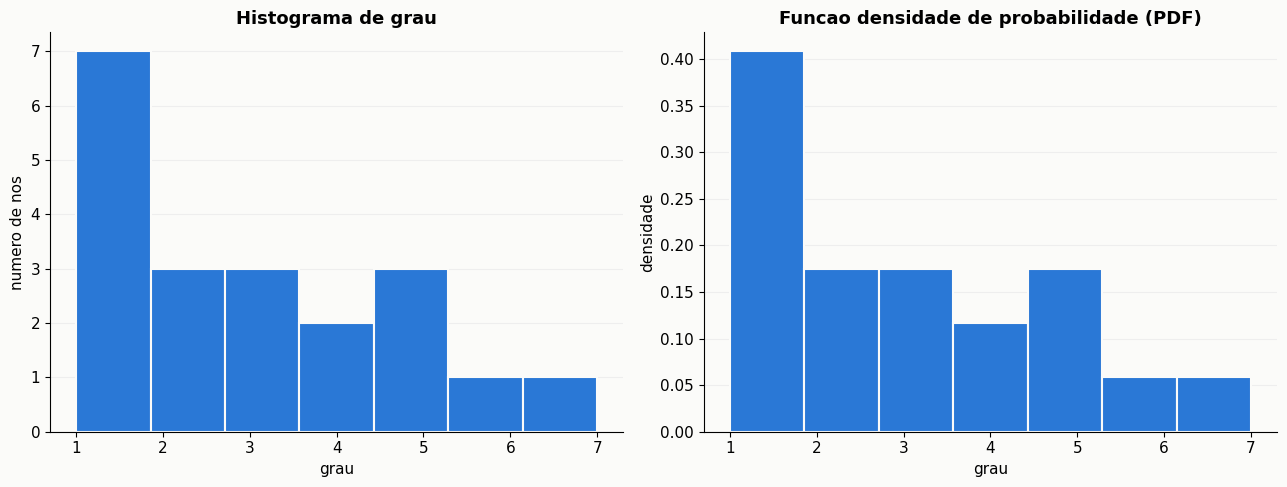

,inicio do bin,fim do bin,contagem,largura,densidade (na mao)
0,1.00,1.86,7,0.857,0.408
1,1.86,2.71,3,0.857,0.175
2,2.71,3.57,3,0.857,0.175
3,3.57,4.43,2,0.857,0.117
4,4.43,5.29,3,0.857,0.175
5,5.29,6.14,1,0.857,0.058
6,6.14,7.00,1,0.857,0.058


In [20]:
sequencia_grau = sorted([d for n, d in g.degree()], reverse=True)
print("sequencia de graus:", sequencia_grau)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
contagens, bordas, _ = axes[0].hist(sequencia_grau, bins=7, color=CATEG[0], edgecolor=FUNDO, linewidth=1.5)
axes[1].hist(sequencia_grau, bins=7, density=True, color=CATEG[0], edgecolor=FUNDO, linewidth=1.5)
axes[0].set(title="Histograma de grau", xlabel="grau", ylabel="numero de nos")
axes[1].set(title="Funcao densidade de probabilidade (PDF)", xlabel="grau", ylabel="densidade")
for ax in axes: ax.grid(axis="y", color="#eee"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

largura = np.diff(bordas)                    # largura de cada bin
pdf_na_mao = contagens / (contagens.sum() * largura)
pd.DataFrame({"inicio do bin": bordas[:-1].round(2), "fim do bin": bordas[1:].round(2),
              "contagem": contagens.astype(int), "largura": largura.round(3),
              "densidade (na mao)": pdf_na_mao.round(3)})

A **densidade** de cada barra é `contagem / (total × largura)`. A área total das barras é 1. Confira que a coluna "densidade (na mão)" reproduz as alturas do painel direito. Um detalhe que costuma passar despercebido. Quando os *bins* têm largura menor que 1, a densidade pode ser **maior que 1**. Densidade não é probabilidade.

### Desafio 5 · O histograma mente?

Use a figura interativa abaixo e arraste o controle de *bins*. Em seguida responda. Com 3 *bins*, quantos "picos" a distribuição parece ter? E com 12? Qual dessas duas versões descreve melhor a rede? Justifique.

<details>
<summary><b>Gabarito</b></summary>
Com poucos <i>bins</i> a distribuição parece ter um único pico e cair suavemente. Com muitos <i>bins</i> cada grau vira uma barra isolada (sete nós de grau 1, depois barras de altura 3, 3, 2, 3, 1, 1) e a figura sugere "buracos" e picos secundários que são apenas ruído amostral de 20 nós. Nenhuma das versões é "a verdadeira". Por isso, para comparar redes, preferimos a CDF, que não depende de <i>bins</i>.
</details>

In [21]:
opcoes_bins = [3, 5, 7, 10, 12, 20]
kmin, kmax = min(sequencia_grau), max(sequencia_grau)
frames = [go.Frame(data=[go.Histogram(x=sequencia_grau, marker_color=CATEG[0],
                                      xbins=dict(start=kmin - 0.5, end=kmax + 0.5, size=(kmax - kmin + 1) / b),
                                      marker_line=dict(color=FUNDO, width=1.5))], name=str(b))
          for b in opcoes_bins]
fig = go.Figure(data=frames[2].data, frames=frames)
fig.update_layout(title="O mesmo grafo, varios histogramas (mesmos 20 nos)", height=480,
                  xaxis=dict(title="grau"), yaxis=dict(title="numero de nos", gridcolor="#eee"),
                  plot_bgcolor=FUNDO, paper_bgcolor=FUNDO, bargap=0.02,
                  sliders=[dict(active=2, currentvalue=dict(prefix="bins = "),
                                steps=[dict(method="animate", label=str(b),
                                            args=[[str(b)], {"frame": {"duration": 0}, "mode": "immediate"}])
                                       for b in opcoes_bins])])
fig.show()

## 5.2 KDE e CDF

A **KDE** coloca uma pequena "montanha" (kernel) em cima de cada observação e soma tudo. O resultado é uma curva suave, boa para o olho, mas que "vaza" para valores impossíveis (repare que a curva existe em grau negativo). A **CDF** acumula a PDF e responde diretamente "qual a fração de nós com grau até $k$?".

Abaixo mantivemos duas escalas verticais (contagem à esquerda, probabilidade à direita) porque é assim que a figura aparece nos slides e em muitos artigos. Fica a ressalva. Dois eixos verticais numa mesma figura são uma armadilha frequente, porque o alinhamento entre eles é arbitrário. Aqui a curva serve só como **guia de forma**, não para leitura de valores contra as barras.

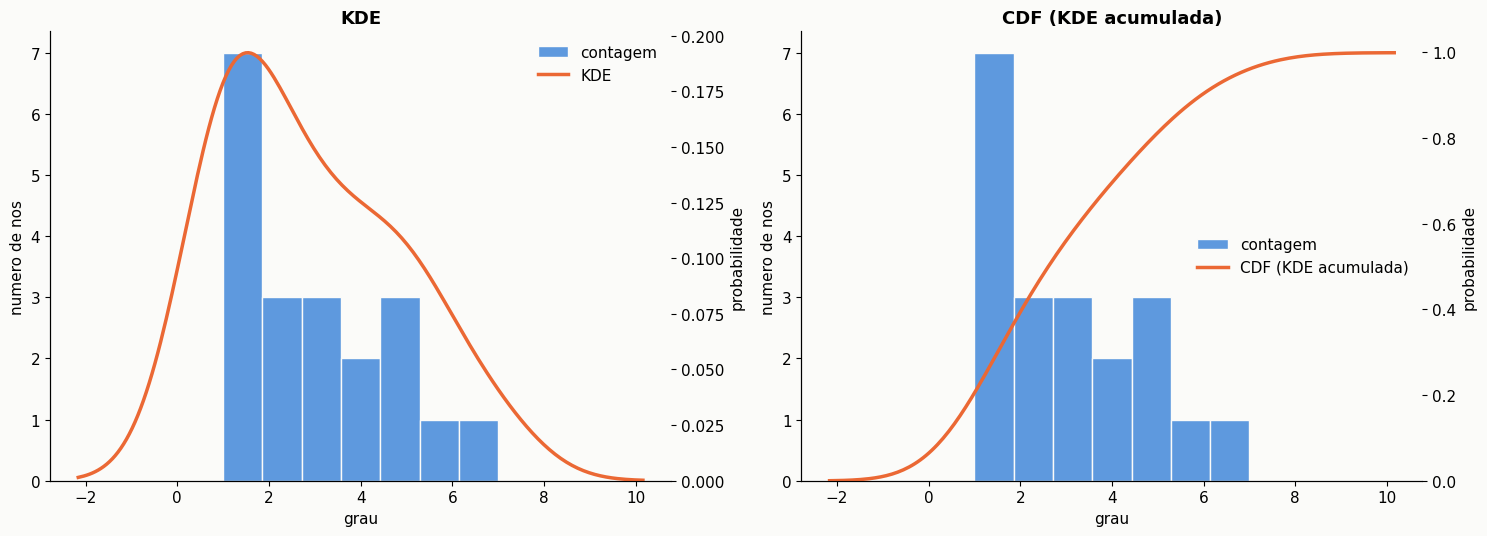

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, acumulada, nome in zip(axes, [False, True], ["KDE", "CDF (KDE acumulada)"]):
    sns.histplot(sequencia_grau, bins=7, color=CATEG[0], edgecolor=FUNDO, ax=ax, label="contagem")
    ax2 = ax.twinx()
    sns.kdeplot(sequencia_grau, color=CATEG[1], lw=2.5, cumulative=acumulada, ax=ax2, label=nome)
    ax2.set_ylabel("probabilidade"); ax2.spines["top"].set_visible(False)
    ax.set(xlabel="grau", ylabel="numero de nos", title=nome)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax2.legend(h1 + h2, l1 + l2, loc="upper right" if not acumulada else "center right", frameon=False)
    ax.grid(False); ax2.grid(False)
plt.tight_layout(); plt.show()

## 5.3 ECDF · a distribuição acumulada empírica

A ECDF é a CDF sem nenhuma suavização. Ordenamos os valores e, para cada um, marcamos a fração de observações menores ou iguais a ele. Não há *bins*, não há kernel, não há vazamento. É a ferramenta mais honesta desta seção.

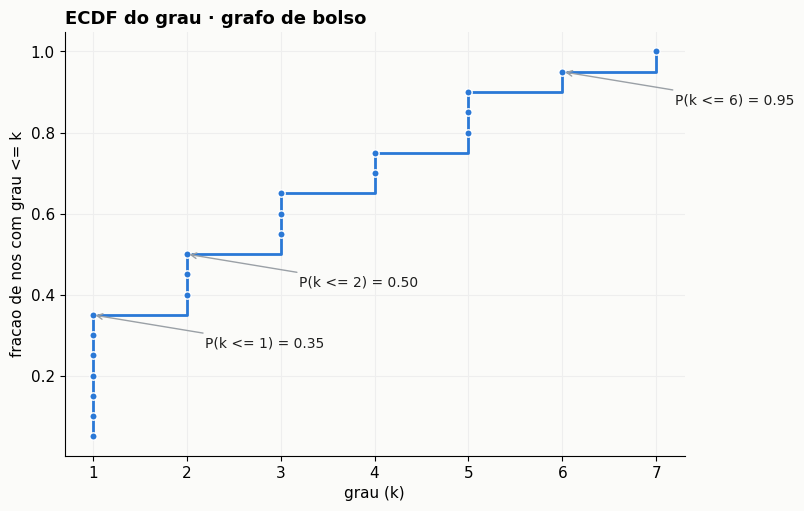

In [23]:
def ecdf(dados):
    x = np.sort(dados)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

def ecdf_grau(G, ax=None, cor=CATEG[0], rotulo=None, degrau=True):
    graus = [G.degree(n) for n in G.nodes()]
    x, y = ecdf(graus)
    ax = ax or plt.gca()
    if degrau:
        ax.step(x, y, where="post", color=cor, lw=2, label=rotulo)
    ax.scatter(x, y, color=cor, s=28, zorder=3, edgecolor="white")
    ax.set(xlabel="grau (k)", ylabel="fracao de nos com grau <= k")
    ax.grid(color="#eee")
    return x, y

fig, ax = plt.subplots(figsize=(8, 5.5))
x, y = ecdf_grau(g, ax=ax)
for k in [1, 2, 6]:
    frac = np.mean(np.array(sequencia_grau) <= k)
    ax.annotate(f"P(k <= {k}) = {frac:.2f}", xy=(k, frac), xytext=(k + 1.2, frac - 0.08),
                arrowprops=dict(arrowstyle="->", color=CINZA), color=TINTA, fontsize=10)
ax.set_title("ECDF do grau · grafo de bolso", loc="left")
plt.show()

Três leituras diretas da ECDF

* $P(k \le 1) = 0{,}35$. Mais de um terço dos nós são folhas (grau 1).
* $P(k \le 2) = 0{,}50$. Metade dos nós tem grau 2 ou menos.
* $P(k \le 6) = 0{,}95$. Só um nó (5%) tem grau maior que 6. Esse é o `s`.

### Desafio 6 · Leia a ECDF sem olhar a figura

Escreva uma função `fracao_ate(G, k)` que devolva $P(\text{grau} \le k)$ usando apenas a sequência de graus (sem `ecdf`). Depois use-a para responder. Qual é o **menor** $k$ tal que pelo menos 80% dos nós tenham grau $\le k$?

<details>
<summary><b>Gabarito</b></summary>

```python
def fracao_ate(G, k):
    graus = np.array([d for _, d in G.degree()])
    return np.mean(graus <= k)

k80 = next(k for k in range(max(dict(g.degree()).values()) + 1) if fracao_ate(g, k) >= 0.8)
print(k80, fracao_ate(g, k80))     # 5 (0.90)
```
Esse valor é o **percentil 80** da distribuição de grau. Percentis são a forma mais compacta de resumir uma distribuição assimétrica.
</details>

In [ ]:
# Desafio 6 · sua resposta
def fracao_ate(G, k):
    ...

# 6. Estudo de caso · SocioPatterns

Em 2009 a Science Gallery de Dublin montou a exposição **INFECTIOUS: STAY AWAY**. Cada visitante recebia um crachá com sensor de proximidade. Sempre que duas pessoas ficavam frente a frente por pelo menos 20 segundos, o par era registrado. O resultado é uma rede de contatos físicos reais, descrita no artigo *What's in a crowd? Analysis of face-to-face behavioral networks* (Isella et al., 2011, [arXiv:1006.1260](https://arxiv.org/pdf/1006.1260.pdf)).

Durante a pandemia de COVID-19 essa pergunta deixou de ser acadêmica. No **rastreamento de contatos**, um nó "importante" é uma pessoa infectada que esteve em contato com muitas outras enquanto transmitia. Mas "muitas outras" é grau. E se a pessoa esteve com poucas, porém em grupos diferentes? Isso é betweenness. A escolha da medida muda quem é testado primeiro.

O arquivo `out.sociopatterns-infectious` tem quatro colunas. Nó de origem, nó de destino, peso (sempre 1) e *timestamp* do contato. O mesmo par aparece várias vezes, uma por contato. Vamos **agregar**. Cada par vira uma aresta cujo peso é o número de contatos. Usamos o dia com mais interações.

In [24]:
# Opcao A: download do arquivo original (mesmo link usado no notebook original)
import os
if not os.path.exists("out.sociopatterns-infectious"):
    !gdown -q https://drive.google.com/uc?id=1REW9CIhtNtdmoO5FrBPeCK5U39p5OMS5
os.path.exists("out.sociopatterns-infectious")

True

In [25]:
# Opcao B (reserva): a mesma rede ja agregada, embutida no notebook.
# Sao 410 nos e 2765 arestas comprimidos com zlib + base64. So e usada se o download falhar.
BLOB_SOCIOPATTERNS = ("eNpNnVeS5TYMRbcyG3hVYgb3vzHzBqD9Yes0xRxAAKTetO/7ta/9+r9G6r9mGr9pmr9hWu8/4/6FKSrJzYjt+y1Ty7dtJ/WvqP+OaIyswph+O05CljCzditz3ZlpZKpYhvu5NvdFVt53/K5guty7XOzdCYevmvpiGQczbeyCYboZ1r4MaxnvZtBtGTIyZLJjW5bdUCRe9Sqnq6tNu+gvXmTYK7tt4cjEZxrul9AS1M0dtXDIcqbugcEBD9Mq+nurWgzWYpluhjUVOWrkB3vF8TzeoJH59XC82Akn4Rpu5voaogxeQ7YgK/sa4leZz+vXK7iMPNmgZdochlkNmjWkk824ot4zbC7Tq00XNMfy4E7UxpAFuTYzR3miNki+amhXlbyqAxe7zfFeHZZoHr/1UngwDKclTEOE4dVzC17kIcpIrujKii5UNASvUgja7KNluuzmXX20a2nv3/kMnv87e2bnbN/IfgouIZh7N2kiRU2fqBEATVOGeF4EWqh0nuCRDYwsOFAwQi7LC9FrwzY11uaWeLoseYi8tm7KoptF3yzxokTDylc7Q07CRZ9hjNWjoMGWguZn2tOgpdAoxLpgON3NOCqufW4ggD2LHmzsqdZcXQxUb0U3aeyiMKlk9IXyII0iLn1QZ893CfNuGvV2on9Jr5Zh3BV4KJqJkXn3m6/HW2hOM7gdde0PTqLuIrWkXVXU1kBS1p1N6SblBzpFoSr27CRSRewzE/dV9EY4kdKG9L98bgYOrghSK+pFWpjEWVnOmbVYO2lXzV6zFO90B51huBlJc2OMHDtSYPaDOrciUsV7LVqmUxRY8ySuT9a2ZwpU+ArV04/Wl9AMwSWAzd01mazJEKm/SfX21STfBmYE6WYu4yvqGW9W2pP5dW+VP6yGQ+hc6C/dT39zir7ncsQtdeGnmrynVvFPu92P8g8qxUtJGOjOhnwgLRszEmzOg+acGnLiUzV+AkeL7acF/NsKDWf8FjFSD07b24yTKhgR8lyoqdlqIFsNUKtRId2kQ3FH6pn2VFoNFolDhB18++XK3CSkMGO5QtgBg/A6TCGSIW8QOFPdD9398Dohn3o4Pyok/beV5pX/4fkGHiPq4RroZT2piKKmHPGf1uvgqGH6/oam9m9ePblqnk6AhTmRTefzRd8ERpvIZ+C59WdQzXqbN9u4EP/gyVIXgl8tt1u8kcvAU7m8gR0KV2W2W75/DnZovErieSn23g5hwfzojoTJaXhyvz7SJ9C1KLsPzlOsHYx/Z2b/uKq02kBvta1mnJJVo6TayJXXJQMwGXvpaX2UUBu5dfWabSBLZdDODHeGrYTLbkaeGLgj7Br6YA1YrWAV8vVLc4Xjy+SeQ8HiRBKDUNckVkCDM5oURTffzi/DlAnUrKYU6ICeYRLIpIongQy6Ga97VoEiw3q91RoFjSTL6c1VnRQmC9NtYYoh80Y2WU2OkMTpFqHdwyibrZdAJR3tMZKozanQqY6KgXWug/ISNGfRdUUkDBD71QMLFWhh3rQ9mk4SZsolak7PUjGm1IkpGhX2xolrUxt99/s3KvMYZ0b1sHwUYSapPjNtxJk2IgqlBDA+gdKFvd5rv2k9Z1zrJVgh505RZLzD3Z1U8c7Jt1EpLFg767dJqzmaZW1PPbCj6nql5d+4s0OAT1Z8idT6NlMlXFrAIldbc3yItE2SVEUoaSPDXMXFKopWZncyltRr9Bjmq9FK4eIMCJMn6tKc83ts40dobWeV4Hg5twzrWhePvAiWe6mv1HauqjCFXVY/UXW4paPdEiCXxTqeum+Ueju+mstfKUbSWkNkJUhaZEuMDFQ3jJ7DAPJ2pDkzRepo0s23r8un0JKDlFl31R/kWnesxdcQzEntryAtVNArbfi1JiZI0xEkm/aR1gZUBu9lkXoVaSYFzVnQS3pIT05NQUMHPZAOflpmBpLSQ7pJexVxwYEO5xypU9Ehjno9M8lZFcatgsQtChQt4wXF16MucUOaRVmtrj2bNIvqrXZyUoatzxXQCKB73bReDeqsu8OkaB1JhkXqX771TAeNDNMOcDjGqNFhNy6RxAZJ8UFq66Hl4Hh7Zbyt3jns5CSoTkZ6x0iLC5XIRUSqkl8vm6LqED1r+ARJz9eTixGtZUtC++sQaYhIm5M0akJCEdXsIy3T4sKKqFwi5xVIOzKJlQa9hYXdIiL3g0cefdJKeotti0bFWzdpV4pdKU7FO62oUxwAg1OWNIt2RtQKBN2s//i+or+wrMLKl5KDtyxddJimKWhSQbifNxWAxMOthX3ZZw5bM8NWvVU/grQWSTTtSZxiJBk8xJ0ZHtpJoPgym6C/jNQrbHBqEKsOsZyNJ/7KqoLWTNqcBqCjbYRIzyCpIr5qYZsnavYu1tB5YwI6TVTqmI7Y5aYDtescWS9I36Xn8N+w7ReAHgk8UYfBFTz4lLYo9a6LJK5neV9A1jk3he9wRGS2hJp+j3Ympj/o9dKAPwNP1HXCpPjND8A6T0+c9wz/Hf77+E9ujCenCSnYffTWtF+SvDjHTcI4TiqgIM060sy3a+fbXSl2vfV6GhxLxzs00UnS04i7AiML0WQDabKRWmYTvYjOYqzIllXwmEa6KnptViTZTI0DkjT9Vv5VjNnr83WFGrhRe2U7OdStduZ2UlyBdsU7FU/rAyZIy7e90npfaMc7bssxeGAF0ybUErom8fdWKlML6+B95ybf09yA5aipFdzOhojzWERXPInuadJgmcRZgasiVoaLTjdSVBgHArSrkN0y3u4ZT/1FWvlWMpg0KIyIs15HZn2qEO06pMzac2GXhQPS7k7qRaPezqJdRMWOVPnJAiZRaJF6ha2inSlO5XwiSdssqdJGxtMcOLUBnuqXEym4T5RYDC6lbbr04QGjkgTVOFIlCZmTJ1LryY0IFfJO2FNPI1GZINHsIN2MF81vJWQ52zcaSeLkBP297d8pQjeTeGYiejMiA59mkKGBzZ/IIwQuJdpIIGdJV+6CB0YIXVKEySPigQiRAl+EKSqCiBDhTMxYxYwqhmJedJO4YTAhDwtAnYqACOuFRB+aCOtKBINEdDPeq1b/jE9/NnH0hDvzGVChRHQdkW6GTUhj0ckUkl2QKjqjBckFP+WFxVx6KEkyc2oCOAfmtCL7wEb5tDRFNih8CCdUXqE3upaZtTRVhqcM6ewMuzJCBv0ycxoH/QfEST8EMTK5zuY2erw7I2//oJYFdttB2Sus3CjSHkC6SV7OOd1Ii2oOTrMmnuiu8a9ZZZNTkG7Q/tM8+dG3ZnOg+9XRHzLqUDK67wgl02caEDN9DLNnv3f3O/ac3xwEafXw2s43HeBLgT8SwHOlVe0CSQyQuEOSqESRJjQ+0qJpToyKyKJA+ytqlDDEnnlLQIJOlSxh+MhiG6QTwi3jcomW3FpE6gQkyfLGyoZpVhJuLKRTJBcwUbpt007lfCzNZc06oky+XebqLoMUdDOFDVLScr1skD7SxN81379q3KfGOVDrgqTGfWwcXMlE6j4kte5j6zKiW/fVpvWpSS4nMnNWYtCjvQZhQvUe9G0/RfMBF0e6K0epqLe0h5uVJfUibhrzpopPWvX2FPEAC7QpAumhovgkLW4foO0wLWbRX1gktVZ0sHSEMC6n+WaE/iXZ55gu7Zn6Y8j3T6fNlZzvmQNozqSlnSEodUT9m0mS86TJ/SfsOBadoptvB06JhRQGoNEy60FPFmkUTW0mXxYM0mZKqrdNRwywMFuG9UqhapFu0iiiMBRVvF1lHG0vX9YZx6SjFc2iVbRdl7GyfmNnLoMKo6hzr4MvkWLz5TBoSgFwvgPgmHEqRFLnyb+Qx4RGnh8K+18E7ApGbp5fDQ5o4r6LCMdSIPqMoU9j18U6bvpbKmpeMLi+4HF9m+M9l95rg3vPo7+X/tQ+s7iwlolmD2nU21lvJWgWF9YwRdLuSYd3pvYqg3+VGrpqL8s1AtJ62OmohZDDrZ1lfCbdNb66dKI3W1D7o1F0kmbRqnhLizNSo2u1oFqUahha29tYrzWdW+TUBWmawucsvYpkze/hQBeKKGlIUKRFVKZIUXQzBc+ZRFRyx/IeQbr0tglPvlZTUNTXik5Sr7AuDXHVIlzUAYepU7NT9fMtNdxRVR2qqnOZX1FW1bKLVDVYWdO+gotwcUicsxcmiD4WIZ1jwpFNhmvtmlbRzuTSckBRDY2qNq+FiXrGu1VZ7QOk7JrRRhEX2NIGOk1SZbSBZtissFUp6Exa2jQ3SZv0armxLSkW2/T3lusX6tinCnSt0884eeZFpDpBOhVTKlQvFarnmsWqp4hYI/d8Eo9WSVF0qQwDJSyJVqvGT044GLiuwUxZsWY1XUbuFLkGM83slTYc5Q7FwVrVjJXGP0kJSvSslToHYrvOh/FM0rfWSbNznTQ710l9C6ST5hVV0XImrKjWRo7bLdnXS+np7gqU4wOIrw4gvnKNf2z2ENmK/tLExT6nIxB5s2DgHNkry6S0o1LIX5VhqkGqGyfVDdTi8CrjmekHO7PyKP8ASXmkFQyyEV+e2yN/bZL8q3LILlLXkRdIpzykUWGzaJnssG6yzY4wqAhGy+qRWD2QXeEtBw+D9H1FveiYtpwC1/YfidfxRDQ9hLxXIMRZoAjufCPUSyIKnCaKUVKnECPyuo8QnSPaNLqJp957D7qpUYH6KaKwBI1W1LPEke2x0wAkk5xUNeNsgHqN+bw+qRdwD26FU2Cvzx20dIX6ikIhnNB4YuRwwgJBi2fob2pReDY/u5+OryJaFtGslFPEOUrntV9AZkZTBU8npnMPT6fYzgsj/AGO8zwu/TgB0/M+zYJhfN9DQRT5GK0LKSxaUuCmJsQ0ckKQoohXD4CYD7SCp3biz9jh8BdSHfjkoxqiXsSBIVmJKWfFlbOiQQBfOSbgP7kjF8ItxwTcF7qsf8tFccsdgbu2TZr/VFcPoT1P093OWX7lyLteFMN4/jC4O1wtBdzGuVoLjsDir7Eyo4HVjTyOvTnbRTdpqB05x0UVjyqJ6Ga8SR/BvXac7B86FxecsAa6FPdPyOt7Rty3M0pb5000KX49dXQSdfSWRhqHJ3gYQVIfNw7Q0ySBqZp6epgqzMPyN+aRc08oDz3x0PxGn6Ozl5Hyl9SLZAcEezrjnZ8TUwskuXuDwiTDtmvRdR2KFEU332KWHCOFPInyh4NOq5skeUekHvh19cQwNq2OznpP03ZG9mp+Gjqnbq1oZDxdZSOdoqyO5jRzjSKLfOJmbbeqqPeoY5hoMJJ4jCk8tOV2yu5v54z5tjtPFBV2M0w6/pzpvp3T04SkXKaW4jD1CjuZVr3NA796K4cBiFKSsdVxvGn2ZRgO/YyrAhdmAYmHQDCFUQzBAbw7jac23eltmhP6LgrPU/152J96q8kvUnceTdRP6K47NZKnuu6kqwAkH/iSvYJ9GDg1LGv5zJ2Czc6MUbJt5DwgSbkvk3BEWVRR3vIob7lWi8NUQ9Kst7wcKqzE49JKiRzJ0dPjNGo58M4OtxWSHAtD4seBtsc6SxkmFdJZyBbZHuvqJSeZK7ORIwM7Ky0WES0qeNUWh5oTUu4x0qYyQ9RIfpLv3agV+6UdCVIfY42+iRciyNrPOOALJFrBaZzewzSkXaXChpMCT+DBfIYJ574kXGNwRLqc0eJcL6um98pVsm5Z0TAoGs1HEN24Il4RI8IL1Y3y7hB7pd8j028eFgj5IYNwZ66bHQiSH4nEngbdrFy/laPMU9Iq2pXiVNg1wVDFxd4//WVPNnGIlhROYtR7t5EorYXY/5A1Iq3KYG8XxYb5vRx0pEhSa0lQ5Ei34mmukXaFqf+J14G68SJqRVGkeCuVlk5/E/t+ywOxTHQIbPkdml9vaizCzum57Xhoxo1lQqqcqFWS3MLlizwiejq2HA8uxq1eHOOkWW93hUVRNisbDTpuQTZ/UaXrpszPzlwSjSohb/XCVWL5CNp/FOwI4uUWzVszjbKNeDKqGkNiRzCSBo7o5F39KKIBTeIFK1ErmkXHNL5VtIvqLa6/mmaFRRHFBqhnGaNXPN42FlWKUfH4ramIq4f0F69yntmOMSvtXPV2F52s6eSRNIg31EQyFImrArmJkqqqvKAlomwF7UqxZZkCT9XmjKLqwVM9yKMyksYGN2C0JHk1LxxmbzypJ/GqloiuQxKnH4naAOlw+hEjI8odR6LsJ41Mwo9vRYttIu4smd8HiqIiXodhqWCzAbbpKnrgY1ajZjUFkonKSVhaZWDnjkiUrkikS5SEMybSlfwISzZndUfGdHNmCvKwuMs0pwqy6ItZDbLoC2NzRb0yQG2yA99c01iTVtEuOkWhDN/Ubooo9W2RuE2ItvrlcBGb6HMx0i4iUREg0TAG8ZNSkTvlsFMc8WrSE1dleSWriCeL9CgfdkqQxpdVG9InSdMVR5+8t7BJJPDpv+GaIJ2kwFGIiG0haesksjGgq92f2DONJixpFrEnSLvi0TMhvI6IBiQ1V9ZijIRZykZyNEhsgKgX4SYyiUuZxPu1IixCUeXHYRFVPH4xKuJlRNIugq4pUhnhCSY6RfWW6wmEIUmCSSjaLDcoyjPsZjx+fCdSuX+9cb3riipM583f9b4KynIvyx2mzdIuy30igogvJ0yZtYXFlNG5RY3K9bSLQOSjoVMkZZXuQ2mrtFDsdxBNLmsQHauinW+19LDZp9eplerd8tzma2XRNltE1AA0U0DcnEW7CMtJdB2GXpomHDMZ4asWYT0LqXmTeOosYr/zOukOwoUm+EDeAQAUEzwd9XDKhVxyeIaelIuIjA1u6nM/PI7/vPp7UvYA8Hk/gWYLYPkV/cvTX8jwcpCe3MLw7H4ePaGt8Nn9dNm8A4en44Xz0WnF1eWBnngS5eol6Tv9m5ooqd98y0thop3x7NxaHlVRJC19knWlxoZI2ruQe5ewZzGbh7NXSmy9Pln2qRJPlXOrbF0/udJElaHGn9MTYm39k4fH3r3tqU7SB11324FN0ueApF10iirtlF/rVH8eGzIk+kxFSnFsgYp2hdVbezWPzypF8i+sXJ7fSk8D7VWd57a6s9C+PETYZeXuXLIkamf8TPSju3/npkOSjbvTXiDp9setc2Q5PXkx8NLw7yaaMt3+zwzksUCX2zNJqghQlu9o6WIGjVm0i6ibkri7DomXJB3t5nCS7JDQ0E2TrgOWd2tomCDDgEO7/TjlFTlZ7XGqlBqU8eeYanlwPVs2ebbyjeUGxMUxqZevSkuKDNtsE6lJMJ86aF6n7D0iO4dEe2+dstpP2rFLys4U3XprS/6U1X5SdV2l1KyTez2qt71PWEeZRpUSrFi+Vr2kwmxTZD6uoZSZpMgUt/LjL5CIruO5NltaxrjGLsPxyzqQsD2I2JZdZuGW7jFNK8Ns935l95bRSKL9sr80+/ZXdm9jFbbJ5njLbiBxZuyW3QCyOd6y8SDZm6SWGboyrSrTyghvVZnGynSSleVtm7YbdwXKMu/l6ei5wkF3ZNitbKTjQzLYvi9TFvq2cx7V06PyGznj9siR3SNnF3RCmQckNWSn2rtL7oDcCbs6YZdpQuShA8vXnNqnyjuVRvN6mGRSHpoedDYcbi7zCTXcYDqD9mqkB+VIm+wmHRccqITDr93vV2O7TZ0OBqK8UrflggRd6fMt7bCrcV4mFng14mE6lc2lMMMvxuhgF9Smi9YOyF7QpAPxIrxIjrMrfwcMu+t5cIRXLs4rl8c1ycK8VtmcwaUCJuQNodvT3rnlCbk9bcBbHo4rN+MxccCuVOVhCtWiPI7XHsdpXGyQXI4Zdpx31sFa81Ole820r46uv9qE+sl7Q/1P7N/aSG76rrF1MAwXyZaey3+v/HvrufN59OQVDzybn91PqEsEWL4E1IbAD14f8BYDns6TF4jO0jVVPI+eqoO/K35Purbe8/BEE8DDUQBN7Ae8PXL8a0rHH0PjSgeWCb6uOPobHz4GgT44XBjBXMeThZ4fVSI8p/5Www8TEIKDArNi+pjzxx/c6e2nK2c/fbBg5x+M5kZbrZk0c6OV90Yrqvn9ldALraQwrb9ATpTQqlkieaSj9qmo3Smi3AYypSFoImoSRtSqiEjHd0T5BcpwjpIVkQanaGVYY23RHToh6LVfQGOQ9TXL4Y6bl7oNjE/2+SEsfIma3qRWxF8bMlKpEPZM44//WprE+NybnkxSh0Yigr4O/yOdtaaTYeOpk5+Rpx3C8cwrI4+biTIH+ZEhr7Ti20DqZqSJj3lFdAOQesbTl4gg3Rlnvq7QZDVwJZZII52EdMbImLpNy1r9EQZLxAJ52XYU8bdYhKcCg0lW1hG0dpIzXP/PcFdaWZik9XPOQccD6RTdjEfPjYhflwzeVucQkZTh9uQgjT8KJt5ZhTXSa7HU7V2k6pNuEm9AirBuRDSUSdj/jSez2ZX10Q163WvGBNy62MwL95+S/8M7Dp+J1d4tBwBEvZukKoKk/wnpISKxfbtnC0D0QtF3JGly5T4N08owr/I7y09mT2i+p1Z7Z20wM5finbUD73Q4k7Sh7ZJOxJWvr27r380cr0iOnjatrZKonYlWvqWbmZ/KvM0GgGHsBHb61S/r4bn8PHrS54CD2emn33OPGrqKPXkD6+DJk0n9+kj/lz8+grs4Okecyrd7b8OT4m7pm2Ie2OvJT4UB3Kje8ziCnBraK/6dpvP8w4tam8+pvw9/1pOED4EIb+QPIByHh5Z4ovZH37h+AKoHL7oyG8hsLwK/rjr+hS+MqHsZd1Y+fn9CbC0DjxyIP1mQ/JE3tAwg/1r02qR6udp7WhPhQyRFtHJNJ8dNCt5QuT6MG0Za4XeV3ndqRsvJHSL6Szm5pPOEsxFm4lGJdSoRJi0HtAnWLLRbee5BQ78IJqSQIkW+1oaCje8USYTBz/lNejhXOvE+nRc2I39UUOh85DRfJi5Eotx9oK7jpck64miUSMV28CekePpLlIABUWcj0asmYhMRfehD90NBlMT1RzoVL5Jo8In+wm6SNL5PFwQx6fy3tLOPTkdBKAA/D8EnjqOOb0O/Jz+woHtawh7Uvgzjhz0iCZDQaIl60GsKgs+YZNds8CTQdCrs7EzBHyURhdywwaO5IYovI+p0StgznxgUYqD595ree5L6aZYyoirGFo6bgdoBumo2TacIfSW61FpUsZ4IY0MEi100MkP+UIJI2/fgLJjT2LX5j9ryR+kQUktMq8J8EWlwhoVpkIJ5NxMlDoQ45G0Y1Y1EzkCSSrk8wM0wdgSJF3OI+p0G0s4kvJtO0vaIwvjZFQn+qjD2CqS6QYoKu+wI4OKgk25G1DZCqlKOtLfG8obIhTQ2aiSuCqyIsBWcWkuWtJLo/BJFhv2Vp4Mf0k3SrEQH4ncnwniodC5NsU+42h9yFybxDo1wZSJ+vmk8FZPTkXS5KQO13ZJW0qkwSGbXSIrglCKYrzUKUP9a5q0zSg7VJ216sznTFNShN+uYdDLeUoa7RnCn0ALx2EEUGRY6hCHuDLxqwGFxQ8SrAyKuLNKqsE31lXgqkAoq6WYYbs6YNDkkalFcaISGkeYJSSZCVHnB8sJE57QwNJQhPdFRNw+cSKsoskTJxlUa6mq5LEFLKnHLSizN1Wna9ZbTjcRJQqIzn6ipgU91kHgbqTgJKYxJUcQuA0mdJs3MhzcwRFzyq4wYkBugeZ7EHlurStOMHqbLaq8cllWWBojX4UXq7aW5htW0dqXeTJ20M7VreCrHUx2rSdIy8Ba6pVFpomoRfxEjhfKK6pJLqdREEsWg1VXxW0lulXKr3jeXC+jMTHx2hd0sRMY1Sd8e3zKMKgW03l2kRQeiWiuqMJ0jQy+WrUf6C+PYnpGazBnZM8f70TZOB1p64OcteBRGkiQl8aD7WBYMI391kRg84xPCLhL1opEZ8cdrRNz/z9EALKFURhLvmQi1swFDx7ZEbZFEFXRS0yBNVe5Wg24197KgaYp8Ky2G1CqMM49EOUbiGIUM9y5Sa6LM9ZCUTqJQiRTSnfbQ+AjsxE7n2eRTl2V+PCAD6PuYkNHynlwMuPUr5/SgsjvvP+5zMM8arL7D54QGM/l5yytuNhty7UcBhefy30fPS4MadeCnvZMG5CXglBjAKT+ndNU5ZTK956Va9Q1bSbBkYF3sQ5StgIC0Gg6VUxN/txVKbeqANgb+QakdXcvxp82Ov347flILb66ZXmPZNZbX1CqMe0TXWGL0I9WUUzrssQ77GXu95jWW86fDntIVSX/5XN7cAF5+vYKcPfNImjOfyvFrVY00MqKWClyUTtxSdSWNClO8ns1CTU2zpmO5fUDOb6va0c0UvCAJF9IyWT5ELaK4uVpBdEeT8JOPpp5v+ZmQ8fr1/L4i7likyV8eI3KSkML5zO8maWrwS3pYz8J5M9C695fWHcx7NWBXR+C3JP0jD5FpZ+nbsxTl/efW+soVOfV2EiGCUYidLUcXOPCUNPspn5PyG6QLZ8KnmX3ErCOI8oR0irj/4rvLw58iFUsrBPEYEJQ7wczOO3IZLlIO5eHwdtJfGMdAJMMSvgb5nu7NqUE6JqQdpu54HtN7M797c1e6GlK4kT7nwrkAf9oyTnqdPkacppsROfaIg0KWiX4o4anX6C8SWwIHIQYET54+4NY4r1gD+MkAAKdym46xjif9I3jyJw5+zFL/EAFaq/4AoTJjG6XA9VQZcCTHI+3N05Q7CdwBMPoaJAz5pB9INNhF27mJeJ0FD42wSH0ZTPxo0Nc3ALpoNHwxaOhiEC7eUCHaunHUCfCy4Sdf2Nql1gd+dvv8g11N90PIa/iejHbCR0f+STacx00/82/U7frf7rj6pzsUwBOU63+w4y555hZLeiYQADvhvz21U22ermEeYdbSkQHfJ7sG8m9hmwnuReMffjeUX1y+RPz5zqXU37/3/0UfEa7b82c619bI4j4MP5Pc8s68scKdMfyaUPjXBfGk/ynY4JcYgDUX/rc77tA/q3L9b7xc/ssul0+2c+gf0bhDv3cexzm/5/ATF1UIUB3j6FQO22joeTh22KyYEkrQFQRd6gBc8vt39Y8G8Qlhcv1va1z+0xqvl+5PP2eAT0ZhT96jf/nlHifwr7K/KoWfynD+PbeffN9/3CTxD8psP1FpPPH+8l9LafEf9aPrNw==")

def rede_embutida():
    texto = zlib.decompress(base64.b64decode(BLOB_SOCIOPATTERNS)).decode()
    G = nx.Graph()
    for tripla in texto.split():
        u, v, w = tripla.split("-")
        G.add_edge(int(u), int(v), weight=int(w))
    return G

In [26]:
def rede_do_arquivo(caminho="out.sociopatterns-infectious"):
    df = pd.read_csv(caminho, sep=" ", skiprows=2, header=None)
    df = df[[0, 1, 2]]
    df.columns = ["pessoa1", "pessoa2", "peso"]
    # agregacao vetorizada: cada linha e um contato, o peso da aresta e o numero de contatos
    contatos = df.groupby(["pessoa1", "pessoa2"]).size().reset_index(name="weight")
    return nx.from_pandas_edgelist(contatos, "pessoa1", "pessoa2", edge_attr="weight"), df

try:
    socio, df_contatos = rede_do_arquivo()
    print("rede lida do arquivo original")
    display(df_contatos.head())
except Exception as e:
    print("download indisponivel, usando a rede embutida:", e)
    socio = rede_embutida()

print(f"SocioPatterns: {socio.number_of_nodes()} nos, {socio.number_of_edges()} arestas, "
      f"conexa = {nx.is_connected(socio)}")
print(f"Grafo de bolso: {g.number_of_nodes()} nos, {g.number_of_edges()} arestas")

rede lida do arquivo original


,pessoa1,pessoa2,peso
0,100,101,1
1,100,101,1
2,100,102,1
3,100,103,1
4,100,103,1


SocioPatterns: 410 nos, 2765 arestas, conexa = True
Grafo de bolso: 20 nos, 29 arestas


> Se você quiser reproduzir o laço do notebook original (um `for` sobre as linhas somando 1 ao peso), ele está no gabarito do Desafio 7. A versão com `groupby` faz exatamente a mesma coisa em uma fração do tempo, e essa diferença importa quando a rede tem milhões de contatos.

### 6.1 Retrato da multidão

410 pessoas e 2 765 pares. Desenhar tudo com a mesma ênfase produz uma "bola de pelos" (*hairball*) ilegível. A saída é Gestalt pura. Só os **10 maiores hubs** ganham cor, rótulo e tamanho; os outros 400 viram fundo. Passe o mouse sobre qualquer nó para recuperar a informação que a figura escondeu de propósito.

In [27]:
POS_S = nx.spring_layout(socio, seed=123456789, k=0.3)

metricas_socio = {
    "degree":      nx.degree_centrality(socio),
    "closeness":   nx.closeness_centrality(socio),
    "betweenness": nx.betweenness_centrality(socio),
    "eigenvector": nx.eigenvector_centrality(socio, max_iter=1000),
}
grafo_interativo(socio, metricas_socio, pos=POS_S, titulo="SocioPatterns · INFECTIOUS 2009",
                 top_k=10, altura=700, tam_min=4, tam_max=30).show()

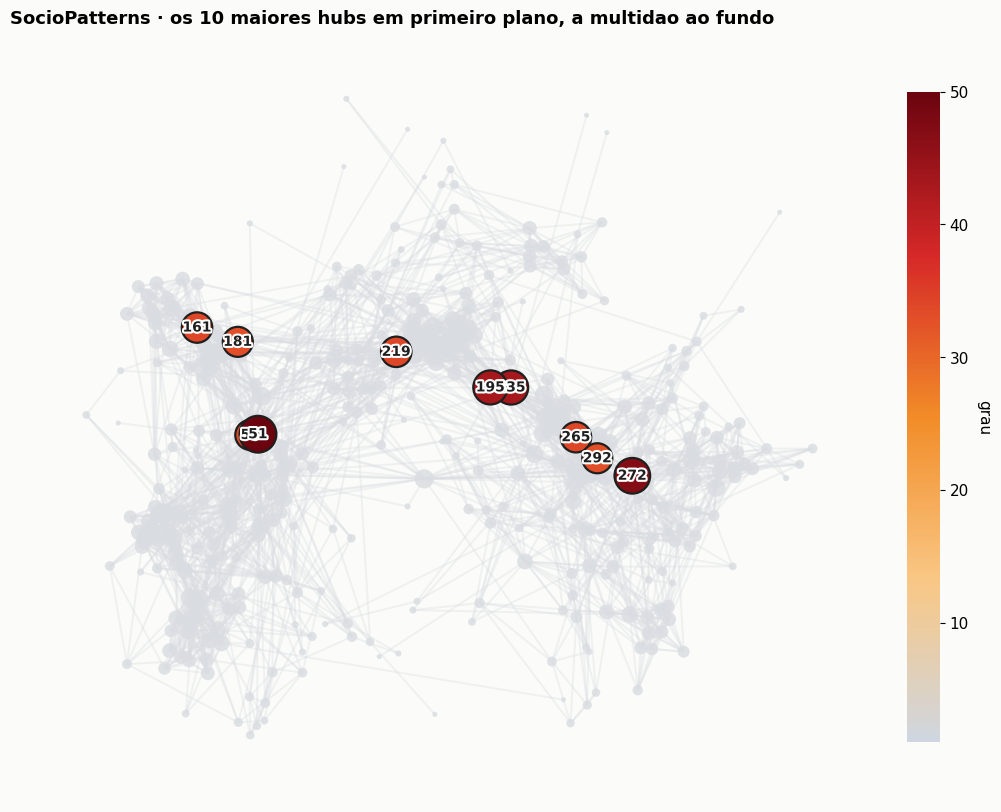

In [28]:
grau_socio = dict(socio.degree())
top10 = sorted(grau_socio, key=grau_socio.get, reverse=True)[:10]
fig, ax = plt.subplots(figsize=(12, 10))
desenhar(socio, grau_socio, pos=POS_S, ax=ax, destaque=top10, rotulo_barra="grau",
         tam=(30, 700), titulo="SocioPatterns · os 10 maiores hubs em primeiro plano, a multidao ao fundo")
plt.show()

### 6.2 Como comparar redes de escalas tão diferentes?

Um grafo de 20 nós e outro de 410. Grau máximo 7 contra grau máximo 50. A pergunta dos slides é exatamente esta. **Como comparar centralidades de redes com escalas diferentes?** A resposta é a distribuição acumulada. E, como os graus se espalham por quase duas ordens de grandeza, o eixo horizontal em **escala logarítmica** deixa as duas curvas legíveis ao mesmo tempo.

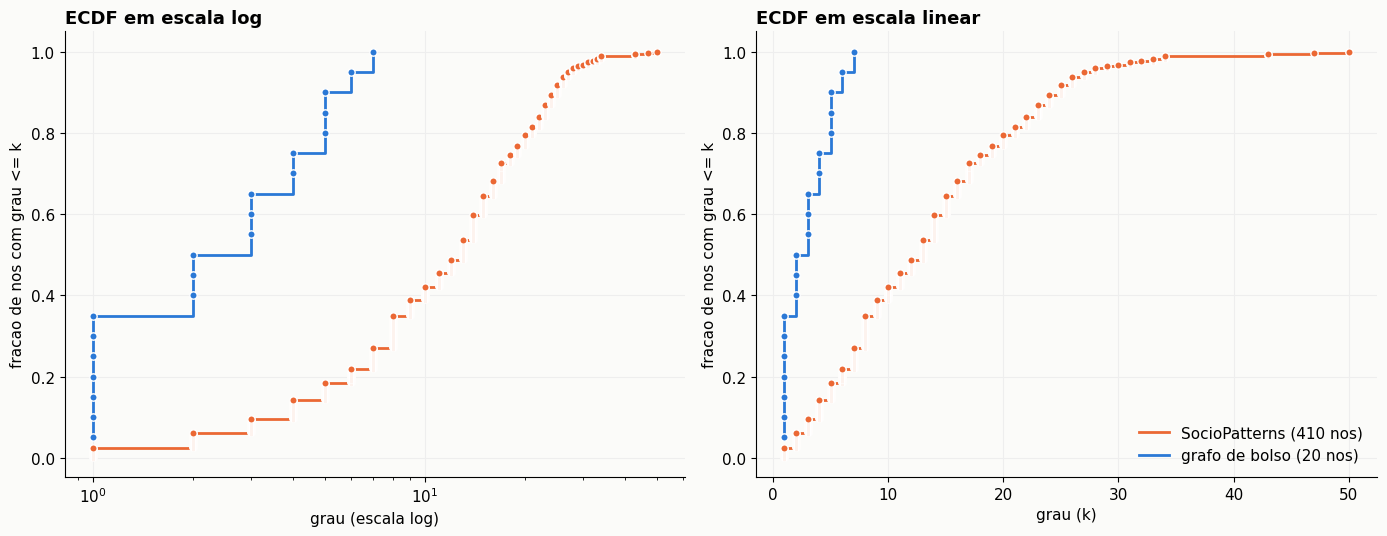

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax in axes:
    ecdf_grau(socio, ax=ax, cor=CATEG[1], rotulo="SocioPatterns (410 nos)")
    ecdf_grau(g,     ax=ax, cor=CATEG[0], rotulo="grafo de bolso (20 nos)")
axes[0].set_xscale("log"); axes[0].set_xlabel("grau (escala log)")
axes[0].set_title("ECDF em escala log", loc="left"); axes[1].set_title("ECDF em escala linear", loc="left")
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

Leia a curva laranja. Metade dos visitantes teve contato com até 13 pessoas, mas existe uma cauda longa. Uns poucos visitantes conversaram com 40, 50 pessoas. São eles que, numa epidemia, importam.

### 6.3 Hub é a mesma coisa que intermediário?

Na rede de bolso `i` tinha grau modesto e o maior betweenness. Isso se repete numa rede real? O gráfico abaixo coloca grau no eixo horizontal e betweenness no vertical, para as duas redes, com **os mesmos limites de eixo** (senão a comparação é injusta).

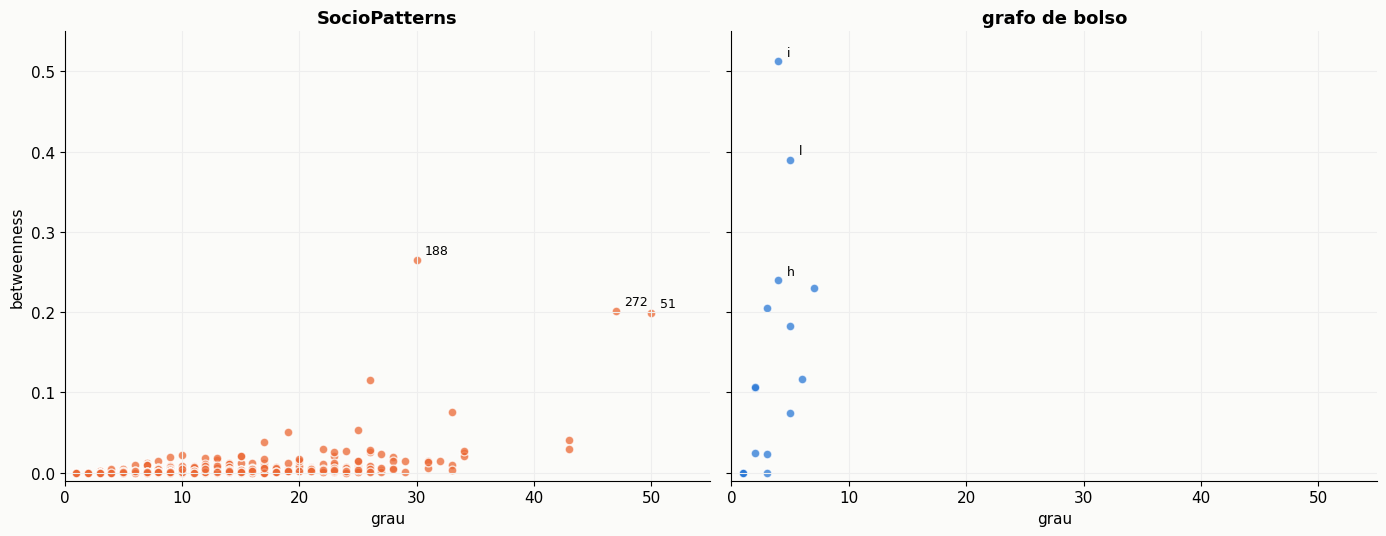

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, (G, nome, cor) in zip(axes, [(socio, "SocioPatterns", CATEG[1]), (g, "grafo de bolso", CATEG[0])]):
    bc = nx.betweenness_centrality(G); dg = dict(G.degree())
    xs = [dg[n] for n in G]; ys = [bc[n] for n in G]
    ax.scatter(xs, ys, s=40, color=cor, alpha=0.75, edgecolor="white")
    # rotula so os pontos "fora da curva": alto betweenness para o grau que tem
    fora = sorted(G, key=bc.get, reverse=True)[:3]      # os 3 maiores betweenness
    for n in fora:
        ax.annotate(str(n), (dg[n], bc[n]), xytext=(6, 4), textcoords="offset points", fontsize=9)
    ax.set(title=nome, xlabel="grau", xlim=(0, 55), ylim=(-0.01, 0.55)); ax.grid(color="#eee")
axes[0].set_ylabel("betweenness")
plt.tight_layout(); plt.show()

Na rede real, o nó com maior betweenness (~0,27) tem grau 30, longe do máximo de 50. E entre os quatro visitantes de grau 40 ou mais, dois têm betweenness quase zero. São pessoas que passaram muito tempo num único grupo grande, e não pessoas que circularam entre grupos. Em rastreamento de contatos, "quem conversou com mais gente" e "quem liga grupos diferentes" são duas listas de prioridade **diferentes**.

### 6.4 Todas contra todas

O `PairGrid` do `seaborn` cruza as quatro medidas. Acima da diagonal, dispersões. Abaixo, densidades (KDE bidimensional). Na diagonal, a distribuição de cada medida. A leitura mais interessante está na coluna do eigenvector. Ela é **bimodal**. Um grupo grande de valores próximos de zero e um grupo pequeno em torno de 0,15. A rede tem um "núcleo" onde todo mundo conhece todo mundo importante, e o resto.

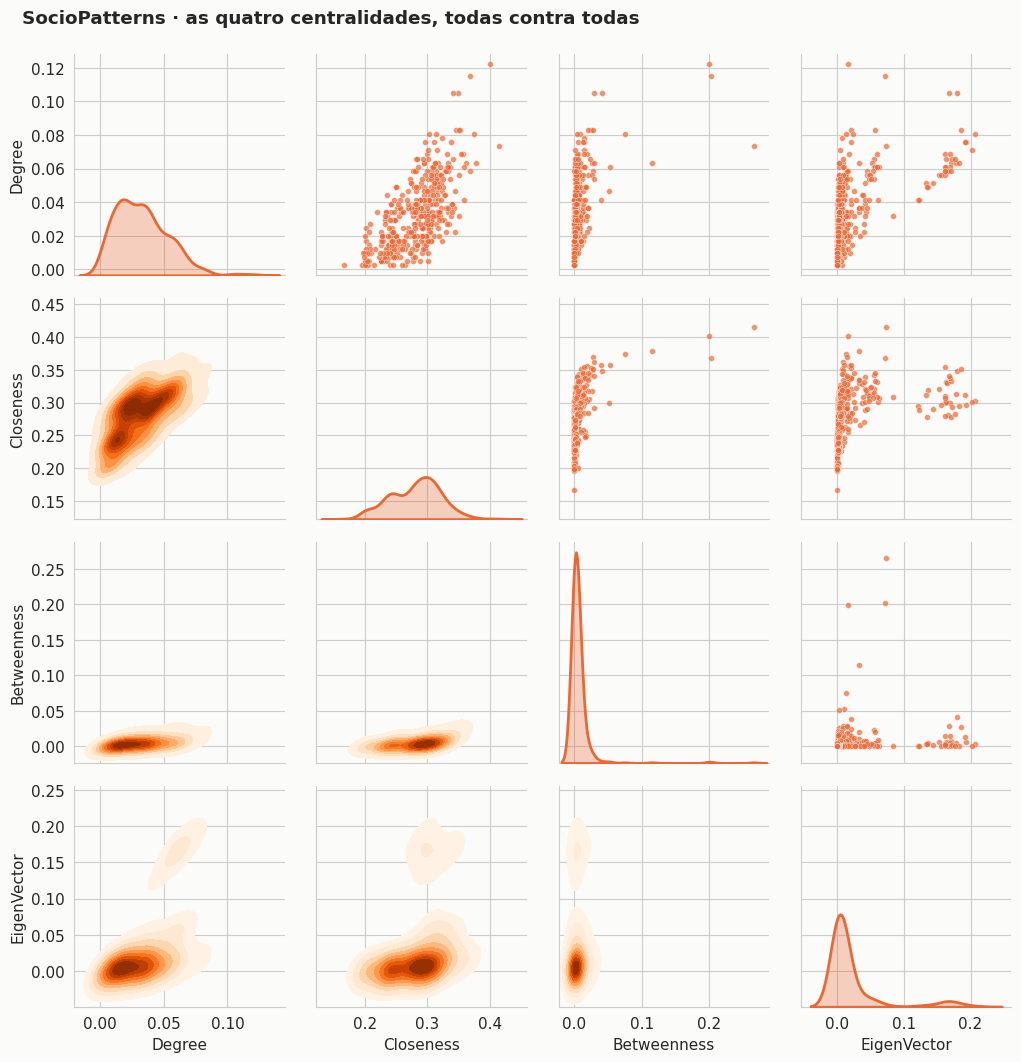

In [31]:
df_socio = pd.DataFrame(metricas_socio).reset_index(drop=True)
df_socio.columns = ["Degree", "Closeness", "Betweenness", "EigenVector"]

sns.set_style("whitegrid", {"axes.facecolor": FUNDO, "figure.facecolor": FUNDO})
grade = sns.PairGrid(df_socio, height=2.6)
grade.map_upper(sns.scatterplot, s=18, color=CATEG[1], alpha=0.7, edgecolor="white")
grade.map_lower(sns.kdeplot, cmap="Oranges", fill=True, thresh=0.05)
grade.map_diag(sns.kdeplot, lw=2, color=CATEG[1], fill=True, alpha=0.3)
plt.suptitle("SocioPatterns · as quatro centralidades, todas contra todas", y=1.02, x=0.02, ha="left", fontweight="bold")
plt.show()

In [32]:
# A mesma grade, interativa: selecione uma regiao em qualquer painel e veja os mesmos nos nos outros
fig = go.Figure(data=go.Splom(
    dimensions=[dict(label=c, values=df_socio[c]) for c in df_socio.columns],
    marker=dict(color=df_socio["Degree"], colorscale=BRASA_PLOTLY, size=5,
                line=dict(color="white", width=0.5), showscale=True, colorbar=dict(title="degree", thickness=12)),
    diagonal_visible=False, showupperhalf=True,
    text=[f"no {n}" for n in socio.nodes()]))
fig.update_layout(title="SocioPatterns · matriz de dispersao interativa (arraste para selecionar)",
                  height=750, width=800, plot_bgcolor=FUNDO, paper_bgcolor=FUNDO, dragmode="select")
fig.show()

### 6.5 Quanto as medidas concordam entre si?

A correlação de **Spearman** compara *rankings*, não valores, o que é exatamente o que queremos (não importa se o betweenness vai até 0,27 e o closeness até 0,45). Quanto mais perto de 1, mais as duas medidas elegem os mesmos hubs.

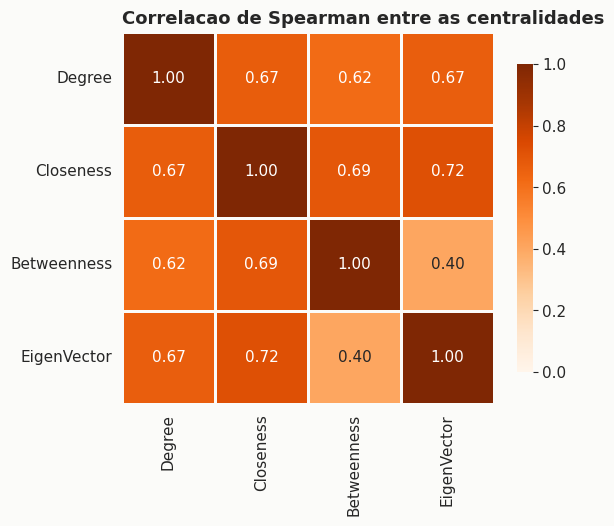

In [33]:
corr = df_socio.corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1, square=True,
            linewidths=2, linecolor=FUNDO, cbar_kws=dict(shrink=0.8), ax=ax)
ax.set_title("Correlacao de Spearman entre as centralidades", loc="left")
plt.show()

Nenhum par passa de 0,72. As medidas concordam em linhas gerais, mas elegem hubs diferentes nos detalhes, e a dupla que menos concorda é betweenness e eigenvector (0,40). Isso justifica a existência de quatro medidas em vez de uma.

### Desafio 7 · O peso dos contatos

Até agora ignoramos o **peso** das arestas (número de contatos entre duas pessoas). Recalcule o betweenness levando em conta o peso. Atenção a uma armadilha. No `networkx`, `weight` é interpretado como **distância** (custo). Duas pessoas com muitos contatos deveriam estar *mais perto*, não mais longe. Crie um atributo `distancia = 1 / weight` e use-o. Depois compare os 5 primeiros do ranking com e sem peso. Quantos nós mudaram?

Bônus. Reescreva a agregação da rede usando o laço `for` do notebook original e confira que ela produz o mesmo grafo que o `groupby` (dica `nx.utils.graphs_equal`).

<details>
<summary><b>Gabarito</b></summary>

```python
for u, v, d in socio.edges(data=True):
    d["distancia"] = 1 / d["weight"]

bc_sem = nx.betweenness_centrality(socio)
bc_com = nx.betweenness_centrality(socio, weight="distancia")
top_sem = sorted(bc_sem, key=bc_sem.get, reverse=True)[:5]
top_com = sorted(bc_com, key=bc_com.get, reverse=True)[:5]
print(top_sem, top_com, len(set(top_sem) - set(top_com)), "mudaram")

# bonus: agregacao com o laco original
socio_laco = nx.Graph()
for _, linha in df_contatos.iterrows():
    p1, p2 = linha["pessoa1"], linha["pessoa2"]
    if socio_laco.has_edge(p1, p2):
        socio_laco.edges[p1, p2]["weight"] += 1
    else:
        socio_laco.add_edge(p1, p2, weight=1)
print(nx.utils.graphs_equal(socio_laco, socio))
```
Com peso, caminhos que passam por pares que conversaram muito ficam "mais curtos", e o ranking muda de forma visível. Não existe *o* betweenness de uma rede. Existe o betweenness **para uma definição de distância**.
</details>

In [ ]:
# Desafio 7 · sua resposta

# 7. Experimento · vale a pena proteger os hubs?

Se as medidas de centralidade realmente identificam nós importantes, então **remover** esses nós deveria machucar a rede mais do que remover nós ao acaso. Vamos testar. Removemos os nós um a um, em quatro ordens diferentes (grau, betweenness, eigenvector, aleatória), e a cada passo medimos o tamanho da **maior componente conexa** como fração do total. Esse é o experimento clássico de Albert, Jeong e Barabási (2000) sobre tolerância a falhas e a ataques.

> **Lente Gestalt.** Quatro curvas, quatro cores fixas, rótulos diretos no fim de cada linha. A legenda existe para o leitor daltônico, mas o olho não precisa dela.

In [34]:
def ataque(G, ordem, passos=60):
    H = G.copy(); N = G.number_of_nodes(); fracoes = [1.0]
    for n in ordem[:passos]:
        H.remove_node(n)
        maior = max((len(c) for c in nx.connected_components(H)), default=0)
        fracoes.append(maior / N)
    return fracoes

random.seed(7)
ordens = {
    "grau":        sorted(socio, key=grau_socio.get, reverse=True),
    "betweenness": sorted(socio, key=metricas_socio["betweenness"].get, reverse=True),
    "eigenvector": sorted(socio, key=metricas_socio["eigenvector"].get, reverse=True),
    "aleatoria":   random.sample(list(socio), socio.number_of_nodes()),
}
PASSOS = 205                       # metade dos visitantes
curvas = {nome: ataque(socio, ordem, PASSOS) for nome, ordem in ordens.items()}
x = np.arange(PASSOS + 1) / socio.number_of_nodes()

fig = go.Figure()
for (nome, y), cor in zip(curvas.items(), CATEG):
    fig.add_trace(go.Scatter(x=x, y=y, mode="lines", name=nome, line=dict(color=cor, width=3),
                             hovertemplate=f"{nome}<br>removidos %{{x:.1%}} · maior componente %{{y:.1%}}<extra></extra>"))
    fig.add_annotation(x=x[-1], y=y[-1], text=nome, showarrow=False, xanchor="left", xshift=6,
                       font=dict(color=cor, size=12))
fig.update_layout(title="Remocao dirigida versus aleatoria · SocioPatterns", height=480,
                  xaxis=dict(title="fracao de nos removidos", tickformat=".0%", gridcolor="#eee"),
                  yaxis=dict(title="fracao de nos na maior componente", tickformat=".0%", gridcolor="#eee"),
                  plot_bgcolor=FUNDO, paper_bgcolor=FUNDO, margin=dict(r=110),
                  legend=dict(orientation="h", y=-0.2))
fig.show()

Duas surpresas. A primeira é que remover nós por **grau** quase não faz melhor do que remover ao acaso. Esta rede é densa (média de 13 contatos por pessoa) e cheia de caminhos alternativos, então tirar quem conversou com mais gente não a parte. A segunda é que remover por **betweenness** a despedaça. Com 20% dos nós retirados a maior componente já cai para 60%, e com metade dos visitantes retirados sobra apenas 11% da rede num único pedaço. A queda brusca perto de 13% acontece quando o último nó que ligava os dois grandes grupos da exposição é removido. Esse é o lado bom (isolar os intermediários interrompe epidemias) e o lado ruim (atacar os intermediários derruba a rede) da mesma propriedade.

### Desafio 8 · Ataque adaptativo

O experimento acima calcula o ranking **uma vez** e remove nessa ordem. Mas depois que o primeiro hub sai, o ranking muda. Implemente `ataque_adaptativo(G, medida, passos)` que **recalcula** a medida após cada remoção e remove sempre o nó de maior valor. Compare com a versão estática para o betweenness. Qual é mais destrutiva? Por que custa mais caro?

<details>
<summary><b>Gabarito</b></summary>

```python
def ataque_adaptativo(G, medida, passos=40):
    H = G.copy(); N = G.number_of_nodes(); fracoes = [1.0]
    for _ in range(passos):
        valores = medida(H)
        alvo = max(valores, key=valores.get)
        H.remove_node(alvo)
        maior = max((len(c) for c in nx.connected_components(H)), default=0)
        fracoes.append(maior / N)
    return fracoes

adapt = ataque_adaptativo(socio, nx.betweenness_centrality, 40)
estat = curvas["betweenness"][:41]
plt.plot(adapt, label="betweenness adaptativo", lw=3); plt.plot(estat, label="betweenness estatico", lw=3)
plt.xlabel("nos removidos"); plt.ylabel("fracao na maior componente"); plt.legend(frameon=False); plt.show()
```
A versão adaptativa é mais destrutiva, porque cada remoção é escolhida na rede que realmente sobrou. O preço é recalcular o betweenness (custo $O(NM)$) a cada passo, o que em redes grandes é proibitivo.
</details>

In [ ]:
# Desafio 8 · sua resposta

# 8. Síntese

### Qual centralidade para qual pergunta?

| Se a pergunta é... | Use | Exemplo |
|---|---|---|
| Quem tem mais conexões diretas? | **Degree** | quem tem mais seguidores |
| Quem espalha algo mais rápido para toda a rede? | **Closeness** | onde instalar um armazém |
| Quem controla o fluxo entre grupos? Quem, se removido, fragmenta a rede? | **Betweenness** | aeroporto de conexão, paciente que circula entre alas |
| Quem está bem conectado a gente bem conectada? | **Eigenvector** | prestígio, PageRank (a prima dirigida do eigenvector) |
| Onde fica o "meio" geométrico da rede? | **Centro / raio** | onde colocar um servidor para minimizar a pior latência |

### Voltando ao seu palpite

In [35]:
campeoes = {nome: max(vals, key=vals.get) for nome, vals in metricas.items()}
campeoes["centro"] = nx.center(g)[0]
print("Seu palpite  :", palpite)
print("Os numeros   :", campeoes)
print("Nenhuma resposta unica. 's' vence em grau e eigenvector, 'i' em betweenness, 'l' e o centro geometrico.")

Seu palpite  : {'mais_importante': '?', 'mais_no_meio': '?', 'sao_o_mesmo': None}
Os numeros   : {'degree': 's', 'closeness': 'l', 'betweenness': 'i', 'eigenvector': 'k', 'centro': 'l'}
Nenhuma resposta unica. 's' vence em grau e eigenvector, 'i' em betweenness, 'l' e o centro geometrico.


### Quiz de saída (autocorreção)

Responda às perguntas preenchendo o dicionário abaixo com a letra escolhida. A célula confere as respostas por *hash*, então não adianta espiar.

1. Numa rede em forma de estrela (um nó central ligado a todas as folhas), qual afirmação é verdadeira?
   (a) o centro tem betweenness zero  (b) as folhas têm closeness igual ao do centro  (c) o centro tem betweenness máximo igual a 1  (d) o diâmetro é 1
2. Um nó com grau 2 pode ter o maior eigenvector centrality da rede?
   (a) nunca  (b) sim, se os dois vizinhos forem os nós mais centrais  (c) só em grafos dirigidos  (d) só se a rede for desconexa
3. Para comparar a distribuição de grau de duas redes com tamanhos muito diferentes, a ferramenta mais robusta é
   (a) histograma com 7 bins  (b) KDE  (c) ECDF  (d) a média do grau
4. Em rastreamento de contatos, se o objetivo é impedir que a doença passe de um grupo para outro, priorizamos pessoas com alto
   (a) grau  (b) betweenness  (c) closeness  (d) excentricidade
5. Removendo nós ao acaso de uma rede com hubs, a maior componente
   (a) desaparece rapidamente  (b) resiste por muito tempo  (c) cresce  (d) não muda nunca

In [ ]:
import hashlib
respostas = {1: "?", 2: "?", 3: "?", 4: "?", 5: "?"}     # preencha com "a", "b", "c" ou "d"

_gabarito = {1: "2e7d2c03a9507ae265ecf5b5356885a53393a2029d241394997265a1a25aefc6",
             2: "3e23e8160039594a33894f6564e1b1348bbd7a0088d42c4acb73eeaed59c009d",
             3: "2e7d2c03a9507ae265ecf5b5356885a53393a2029d241394997265a1a25aefc6",
             4: "3e23e8160039594a33894f6564e1b1348bbd7a0088d42c4acb73eeaed59c009d",
             5: "3e23e8160039594a33894f6564e1b1348bbd7a0088d42c4acb73eeaed59c009d"}

acertos = 0
for q, r in respostas.items():
    ok = hashlib.sha256(r.strip().lower().encode()).hexdigest() == _gabarito[q]
    acertos += ok
    print(f"questao {q}: {'certa' if ok else 'errada ou em branco'}")
print(f"\n{acertos}/5")

questao 1: errada ou em branco
questao 2: errada ou em branco
questao 3: errada ou em branco
questao 4: errada ou em branco
questao 5: errada ou em branco

0/5


### Para a próxima aula · Core Decomposition

Hoje classificamos nós um a um. Na próxima aula vamos "descascar" a rede em camadas (*k-cores*), removendo repetidamente todos os nós de grau menor que $k$, até sobrar o núcleo mais denso. Você já viu uma pista disso na distribuição bimodal do eigenvector centrality do SocioPatterns. Fica a pergunta para levar para casa. Os 10 maiores hubs por grau estão todos no mesmo núcleo? (`nx.core_number` responde em uma linha.)

### Referências

* Newman, M. *Networks* (2ª ed.), Oxford University Press, capítulo 7 (Measures and metrics).
* Isella, L. et al. *What's in a crowd? Analysis of face-to-face behavioral networks*. J. Theor. Biol. 271, 2011. [arXiv:1006.1260](https://arxiv.org/pdf/1006.1260.pdf)
* Meghanathan, N. *Use of Eigenvector Centrality to Detect Graph Isomorphism*, 2015. [arXiv:1511.06620](https://arxiv.org/pdf/1511.06620.pdf)
* Albert, R., Jeong, H., Barabási, A.-L. *Error and attack tolerance of complex networks*. Nature 406, 2000.
* Ma, E. J. *nxviz*, uma gramática de gráficos de rede. [ericmjl.github.io/nxviz](https://ericmjl.github.io/nxviz/)
* Ware, C. *Information Visualization: Perception for Design* (princípios de Gestalt aplicados a visualização).